# Beyond the Cluster: Which Israeli Local Authorities Out- and Under-Perform Their Socio-Economic Standing in National Achievement Tests?

**Introduction to Data Science — Final Project**
Stav Tchizik (316062835) · Or Cohen (206631509)
Ministry of Education Meitzav scores, 2016–2018 × CBS Socio-Economic Index of Local Authorities, 2017 edition

---

## Background

**The Meitzav** is Israel's national school assessment, run by RAMA, the Ministry of Education's National
Authority for Measurement and Evaluation. Pupils in grades 5 and 8 are tested in Hebrew or Arabic as a first
language, English, Mathematics and Science. Schools are divided into three national groups and each group sits
the external test once every three years, which is why most local authorities in our data appear in a single
year rather than all three.

**The socio-economic index** is the Central Bureau of Statistics' standard summary of a local authority's
circumstances. It is built by factor analysis from 14 variables covering demography, schooling, employment and
standard of living, and published for all 255 authorities both as a continuous value and as ten clusters.

**Why the authority level matters.** Education budgets, staffing and intervention programmes in Israel are
allocated to local authorities, so an authority is the unit a decision actually attaches to. The audience for a
question asked at this level is the Ministry of Education and RAMA, the heads of local authorities, and anyone
setting policy on educational gaps.

**What is already known.** That richer authorities score better is documented, including by the Ministry
itself: RAMA publishes a multi-year Meitzav report for each authority, and those reports already compare an
authority against a group of socio-economically similar ones, using the CBS clusters collapsed into three broad
bands. The Knesset Research and Information Center has published related analyses of the index. Reproducing
that gradient would add nothing, so this project asks a different question.

## Research question

**Which local authorities in Israel score higher or lower on national tests than their socio-economic level
would predict, and what sets those authorities apart?**

Two smaller questions support it: how closely the socio-economic index tracks test scores in the first place,
which gives us the baseline the deviations are measured against, and whether grouping authorities by their
achievement profiles reproduces the official CBS socio-economic clusters (1–10).


# 1. Exploratory Data Analysis and Data Cleaning

The proposal's first step: load the two sources, handle missing values and anomalies, resolve the authority
code mismatch so the files can be merged, and plot the distribution of scores across subjects, grades and
socio-economic clusters.

## Setup

Imports and create the random seed, `RANDOM_STATE = 42`. Every step that involves randomness later on (the train /
validation / test split, cross-validation, Random Forests, K-Means) takes its seed from this constant, so the
results can be reproduced exactly.

In [94]:
import random
from pathlib import Path

import numpy as np
import pandas as pd

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

DATA_DIR = Path("datasets")
EDUCATION_PATH = DATA_DIR / "performances_by_areas_years_2015_2019.csv"
CBS_PATH = DATA_DIR / "t01_2017.xls"

## Loading the data

**Ministry of Education Meitzav scores.** A clean CSV with one row per authority × year × sector (`norm_id`) ×
grade (`shichva`) × subject. It loads as is.

**CBS socio-economic index, 2017 edition.** The Excel sheet `t01` was laid out to be printed, not analysed:

- Rows 0–9 are a bilingual (Hebrew / English) header spread over several rows. Rows 8–9 inside that block are
  not authorities but national summary rows (`AVERAGE` and `NATIONWIDE VALUE`).
- The 255 authorities sit in rows 10–264.
- After a blank row, the last 5 rows are footnotes (`*`, `**`, `***`, `(1)`, `..`).

We skip the header block, keep only rows that have a numeric 1–10 cluster (which drops the blank row and the
footnotes). Instead of the multi-row header
we give the columns short English names. Each of the 14 variables the index is built from comes as three
columns: the raw value, a standardized value (`_z`) and the rank among the 255 authorities (`_rank`). The CBS
marks suppressed cells with `..` ("not for publication"), and these become missing values.

Loading the education dataset:

In [95]:
education = pd.read_csv(EDUCATION_PATH)

Loading and cleaning the CBS dataset:

In [96]:

# Each of the 14 index variables appears three times: raw value, standardized (_z), rank (_rank)
# Age ranges in the names come from the CBS header (e.g. _25_54 = residents aged 25-54, _20plus = aged 20 and over)
CBS_VARIABLES = [
    "median_age", "dependency_ratio", "pct_families_4plus_children",
    "avg_years_schooling_25_54", "pct_academic_degree_27_54", "pct_earners_25_54",
    "pct_women_no_work_income_25_54", "pct_above_twice_avg_wage", "pct_below_min_wage",
    "pct_income_support_20plus", "income_per_capita", "vehicles_per_100_17plus",
    "avg_vehicle_licence_fee", "avg_days_abroad",
]
CBS_COLUMNS = (
    ["municipal_status", "locality_code", "name_he", "population",
     "ses_index", "ses_rank", "ses_cluster"]
    + [f"{var}{suffix}" for var in CBS_VARIABLES for suffix in ("", "_z", "_rank")]
    + ["name_en"]
)

cbs_raw = pd.read_excel(CBS_PATH, sheet_name="t01", header=None, skiprows=10)
cbs_raw.columns = CBS_COLUMNS

# Only real authorities have a 1-10 cluster; this drops the blank row and the 5 footnotes
cbs = cbs_raw[pd.to_numeric(cbs_raw["ses_cluster"], errors="coerce").between(1, 10)].reset_index(drop=True)

# Everything but the names is numeric; '..' (not for publication) becomes NaN
numeric_cols = cbs.columns.difference(["name_he", "name_en"])
cbs[numeric_cols] = cbs[numeric_cols].apply(pd.to_numeric, errors="coerce")
cbs[["name_he", "name_en"]] = cbs[["name_he", "name_en"]].apply(lambda s: s.str.strip())

# Int64 keeps the codes as integers despite the regional councils' missing locality code
ID_COLS = ["municipal_status", "locality_code", "ses_rank", "ses_cluster"]
cbs[ID_COLS] = cbs[ID_COLS].astype("Int64")

cbs.head()

,municipal_status,locality_code,name_he,population,ses_index,ses_rank,ses_cluster,median_age,median_age_z,median_age_rank,...,vehicles_per_100_17plus,vehicles_per_100_17plus_z,vehicles_per_100_17plus_rank,avg_vehicle_licence_fee,avg_vehicle_licence_fee_z,avg_vehicle_licence_fee_rank,avg_days_abroad,avg_days_abroad_z,avg_days_abroad_rank,name_en
0,99,472,אבו גוש,7248.002771,-0.782513,65,3,25.0,-0.513179,82.0,...,45.230176,-0.669310,58.0,1308.544593,-0.711301,36.0,4.134406,-0.503326,99.0,ABU GHOSH
1,99,473,אבו סנאן,13694.227719,-0.792104,63,3,27.0,-0.177639,110.0,...,50.561118,-0.243217,107.0,1337.016716,-0.398686,81.0,3.161709,-0.734325,68.0,ABU SINAN
2,99,182,אבן יהודה,13573.675025,1.499467,243,9,34.0,0.996752,216.0,...,72.263342,1.491405,239.0,1482.609738,1.199883,239.0,13.593401,1.743032,242.0,EVEN YEHUDA
3,0,2710,אום אל-פחם,54239.894898,-1.412629,17,2,23.0,-0.848719,51.0,...,48.431102,-0.413466,81.0,1323.869248,-0.543041,61.0,2.327168,-0.932515,32.0,UMM AL-FAHM
4,0,31,אופקים,27612.866876,-0.703221,73,3,26.0,-0.345409,98.0,...,35.470483,-1.449386,17.0,1317.323556,-0.614911,49.0,2.868257,-0.804015,54.0,OFAQIM


### Dataset summary

Rows, columns, years covered and number of distinct authorities in each file (Table 1).

In [97]:
dataset_summary = pd.DataFrame(
    {
        "Ministry of Education (Meitzav)": {
            "rows": len(education),
            "columns": education.shape[1],
            "grain": "authority × year × sector × grade × subject",
            "years": f"{education['year'].min()}–{education['year'].max()}",
            "authorities": education["rashut"].nunique(),
        },
        "CBS socio-economic index": {
            "rows": len(cbs),
            "columns": cbs.shape[1],
            "grain": "authority",
            "years": "2017 (single edition)",
            "authorities": cbs["name_he"].nunique(),
        },
    }
)
print("Meitzav rows per year:", education["year"].value_counts().sort_index().to_dict())
print("CBS authorities with a locality code:", cbs["locality_code"].notna().sum(),
      "| regional councils (no locality code):", cbs["locality_code"].isna().sum())
dataset_summary

Meitzav rows per year: {2015: 734, 2016: 813, 2017: 752, 2018: 522, 2019: 246}
CBS authorities with a locality code: 201 | regional councils (no locality code): 54


,Ministry of Education (Meitzav),CBS socio-economic index
rows,3067,255
columns,12,50
grain,authority × year × sector × grade × subject,authority
years,2015–2019,2017 (single edition)
authorities,251,255


## Restricting the education data to 2016–2018

Our socio-economic measure is the CBS index from 2017, so we keep only the test years around it (2017 ± 1 year).
Comparing scores from 2015 or 2019 to a 2017 index would measure them against an authority's socio-economic
level from years earlier or later. We drop those two years even though that means losing some rows.

In [98]:
YEARS = [2016, 2017, 2018]
in_window = education["year"].isin(YEARS)

year_filter = pd.DataFrame(
    {
        "rows": [len(education), in_window.sum()],
        "authorities": [education["rashut"].nunique(), education.loc[in_window, "rashut"].nunique()],
    },
    index=["2015–2019 (all)", "2016–2018 (kept)"],
)
print("Dropped rows per year:", education.loc[~in_window, "year"].value_counts().sort_index().to_dict())

education = education[in_window].reset_index(drop=True)
year_filter

Dropped rows per year: {2015: 734, 2019: 246}


,rows,authorities
2015–2019 (all),3067,251
2016–2018 (kept),2087,250


### Do scores drift between 2016 and 2018?

If the average score moves a lot from year to year, `year` has to stay in the models as a variable. The overall
mean per year is misleading here, because the subject mix changes. In 2018 grade 5 was not tested in English
or Math. So we compare each subject × grade with itself across the three years. We measure the change in
points and also as a fraction of the overall score standard deviation.

In [99]:
print("Overall mean score per year (mixes different subjects each year):")
print(education.groupby("year")["score"].mean().round(1).to_dict())

drift = education.pivot_table(index=["subject_id", "shichva"], columns="year", values="score", aggfunc="mean")
drift["max - min"] = drift[YEARS].max(axis=1) - drift[YEARS].min(axis=1)
drift["in score SDs"] = drift["max - min"] / education["score"].std()

print()
print(f"Score SD (all rows): {education['score'].std():.1f} points")
print(f"Median spread across years within a subject × grade: {drift['max - min'].median():.1f} points")
drift.round(2)

Overall mean score per year (mixes different subjects each year):
{2016: 542.0, 2017: 549.6, 2018: 554.2}

Score SD (all rows): 39.2 points
Median spread across years within a subject × grade: 13.5 points


year                  2016    2017    2018  max - min  in score SDs
subject_id shichva                                                 
A          5        576.18  595.15  605.24      29.06          0.74
           8        543.70  549.60  565.83      22.13          0.56
E          5        537.95  537.62     NaN       0.33          0.01
           8        513.35  518.25  519.10       5.75          0.15
H          5        535.32  541.07  543.80       8.48          0.22
           8        553.21  551.64  564.71      13.07          0.33
M          5        551.22  564.68     NaN      13.46          0.34
           8        529.17  532.33  543.70      14.53          0.37
S          8        560.41  582.35  576.41      21.95          0.56

**Result:** scores rise between 2016 and 2018 in almost every subject × grade. The median spread is 13.5 points,
and the largest is about 29 points (grade 5 Arabic), roughly 0.7 of a standard deviation. The only flat one is
grade 5 English, which was tested in only two of the years. That much drift is too large to ignore, so `year`
stays in the models as a variable.

## One row per authority, year, grade and subject

`norm_id` is the education sector: `3` is Hebrew-language schools, `9` is Arabic-language schools, and `1` is
the two combined. The combined rows exist only for authorities that have schools in both sectors (mixed
cities such as Haifa, Lod and Tel Aviv-Yafo, and some regional councils). For those authorities the same
students show up twice: once in the combined row and once in their own sector's row.

First we check on a couple of authorities that the combined row really is the sum of the two sectors.

In [100]:
KEYS = ["rashut", "year", "shichva", "subject_id"]
SECTOR_COLS = ["norm_id", "score", "n_students_tested", "n_students"]

mixed = education.loc[education["norm_id"] == 1, "rashut"].unique()
print("Authorities with a combined (norm_id = 1) row:", len(mixed))

# Two examples: Haifa grade 5 English, and Lod grade 8 Math, where the two sectors score very differently
haifa = education[(education["rashut"] == 40006) & (education["shichva"] == 5) & (education["subject_id"] == "E")]
widest = education[(education["rashut"] == 70003) & (education["year"] == 2016)
                   & (education["shichva"] == 8) & (education["subject_id"] == "M")]
display(haifa[["rashut_teur"] + KEYS[1:] + SECTOR_COLS], widest[["rashut_teur"] + KEYS[1:] + SECTOR_COLS])

# The same check on every case where both sectors exist
tested = education.pivot_table(index=KEYS, columns="norm_id", values="n_students_tested").dropna()
print(f"Combined students tested = Hebrew + Arabic in {(tested[1] == tested[3] + tested[9]).sum()} of {len(tested)} cases")

scored = education.pivot_table(index=KEYS, columns="norm_id", values=["score", "n_students"]).dropna()
weighted_score = ((scored["score"][3] * scored["n_students"][3] + scored["score"][9] * scored["n_students"][9])
                  / (scored["n_students"][3] + scored["n_students"][9]))
print(f"Combined score vs. student-weighted average of the two sectors ({len(scored)} cases with scores): "
      f"largest difference {(scored['score'][1] - weighted_score).abs().max():.2f} points (scores are rounded)")

Authorities with a combined (norm_id = 1) row: 19


,rashut_teur,year,shichva,subject_id,norm_id,score,n_students_tested,n_students
401,חיפה,2016,5,E,1,551.0,859,726.0
409,חיפה,2016,5,E,3,552.0,768,650.0
417,חיפה,2016,5,E,9,543.0,91,76.0
1171,חיפה,2017,5,E,1,546.0,936,822.0
1179,חיפה,2017,5,E,3,546.0,751,660.0
1187,חיפה,2017,5,E,9,546.0,185,162.0


,rashut_teur,year,shichva,subject_id,norm_id,score,n_students_tested,n_students
509,לוד,2016,8,M,1,513.0,443,264.0
516,לוד,2016,8,M,3,555.0,222,185.0
523,לוד,2016,8,M,9,413.0,221,79.0


Combined students tested = Hebrew + Arabic in 87 of 87 cases
Combined score vs. student-weighted average of the two sectors (77 cases with scores): largest difference 0.74 points (scores are rounded)


The combined row is the sum of the two sectors. Its students tested always equal Hebrew + Arabic, and its score
is the two sector scores averaged by number of students (up to rounding). So for each authority, year, grade and
subject we keep the combined row where it exists and the single sector row everywhere else. For the mixed
authorities, every authority / year / grade / subject has a combined row, including subjects taught in only one
sector, such as Arabic.

In [101]:
rows_before, authorities_before = len(education), education["rashut"].nunique()

has_total = education["norm_id"].eq(1).groupby([education[k] for k in KEYS]).transform("any")
education = education[~has_total | education["norm_id"].eq(1)].reset_index(drop=True)
assert not education.duplicated(KEYS).any(), "still more than one row per authority / year / grade / subject"

print(f"Rows: {rows_before} -> {len(education)} ({rows_before - len(education)} sector rows dropped)")
print(f"Authorities: {authorities_before} -> {education['rashut'].nunique()}")
print("Rows per norm_id now:", education["norm_id"].value_counts().sort_index().to_dict())

Rows: 2087 -> 1793 (294 sector rows dropped)
Authorities: 250 -> 250
Rows per norm_id now: {1: 207, 3: 1025, 9: 561}


## Joining the education data to the CBS index

The two files number authorities differently, so we build a join key from the education code (`rashut`):

- **Cities and local councils:** the education code is the CBS locality code with one extra digit at the end,
  so dividing by 10 gives the CBS code (Ofakim is `315` in the education data and `31` in the CBS data).
- **Regional councils:** these have no locality code in the CBS file. Their council number is in the
  `municipal_status` column, and their education code is that number × 100,000.
- **Four merged cities** follow neither rule, so we map them by hand.

A locality code and a council number can be the same number, so the key also records which kind it is: `L31`
is locality 31 and `R31` is regional council 31.

In [102]:
# Merged cities whose education code is not CBS code × 10 + one digit
MANUAL_LOCALITY_CODES = {
    13508: 195,   # Kadima-Zoran
    13516: 1200,  # Modi'in-Maccabim-Re'ut
    13524: 9800,  # Binyamina-Giv'at Ada
    13573: 9400,  # Yehud-Monosson (listed as Yehud in the CBS file)
}

def join_rule(rashut):
    if rashut in MANUAL_LOCALITY_CODES:
        return "manual"
    return "regional council" if rashut % 100_000 == 0 else "locality code"

def cbs_key_from_rashut(rashut):
    if rashut in MANUAL_LOCALITY_CODES:
        return f"L{MANUAL_LOCALITY_CODES[rashut]}"
    return f"R{rashut // 100_000}" if rashut % 100_000 == 0 else f"L{rashut // 10}"

cbs["cbs_key"] = [f"L{code}" if pd.notna(code) else f"R{status}"
                  for code, status in zip(cbs["locality_code"], cbs["municipal_status"])]
assert cbs["cbs_key"].is_unique

authorities = education[["rashut", "rashut_teur"]].drop_duplicates().reset_index(drop=True)
authorities["join_rule"] = authorities["rashut"].map(join_rule)
authorities["cbs_key"] = authorities["rashut"].map(cbs_key_from_rashut)
authorities = authorities.merge(cbs[["cbs_key", "name_he", "name_en"]], on="cbs_key", how="left")

### Verifying the join

1. Every education authority must find a CBS row. Any that don't are printed, and the cell stops.
2. The Hebrew names on both sides are compared after removing spaces, hyphens and apostrophes, so that spelling
   differences like `מג'אר` / `מגאר` don't count. The remaining differences were each checked by hand and are
   listed with the reason. If a new difference appears, the cell stops so we can look at it.
3. CBS authorities with no education data are counted. These are not errors, only gaps in coverage.

In [103]:
unmatched = authorities[authorities["name_he"].isna()]
if len(unmatched):
    print("Education authorities with no CBS match:")
    display(unmatched[["rashut", "rashut_teur", "join_rule", "cbs_key"]])
assert unmatched.empty, f"{len(unmatched)} education authorities did not match a CBS authority"

# Name differences that remain after normalising, each checked by hand
REVIEWED_NAME_DIFFERENCES = {
    10611: "renamed: Nof HaGalil, formerly Nazerat Illit",
    13573: "merged city: CBS lists it as Yehud",
    6600000: "spelling: בוסתאן / בוסתן",
}

def normalise_name(name):
    return name.translate(str.maketrans("", "", " -'\"`׳״"))

name_differs = authorities["rashut_teur"].map(normalise_name) != authorities["name_he"].map(normalise_name)
name_check = authorities.loc[name_differs, ["rashut", "rashut_teur", "name_he", "name_en"]]
name_check["reason"] = name_check["rashut"].map(REVIEWED_NAME_DIFFERENCES)
print("Matched pairs whose names differ:")
display(name_check)
assert name_check["reason"].notna().all(), "a name difference that hasn't been checked - look at the rows without a reason"

cbs_without_education = cbs[~cbs["cbs_key"].isin(authorities["cbs_key"])]
join_coverage = pd.concat([
    authorities["join_rule"].value_counts(),
    pd.Series({"unmatched": len(unmatched),
               "CBS authorities with no education data": len(cbs_without_education)}),
]).rename("authorities")
display(join_coverage.to_frame())
print("CBS authorities with no education data:")
display(cbs_without_education[["cbs_key", "name_he", "name_en", "population", "ses_cluster"]])

Matched pairs whose names differ:


,rashut,rashut_teur,name_he,name_en,reason
26,10611,נוף הגליל,נצרת עילית,NAZERAT ILLIT,"renamed: Nof HaGalil, formerly Nazerat Illit"
93,6600000,בוסתאן אל מרג',בוסתן אל -מרג',BUSTAN EL-MARJ,spelling: בוסתאן / בוסתן
136,13573,יהוד - מונוסון,יהוד,YEHUD,merged city: CBS lists it as Yehud


,authorities
locality code,192
regional council,54
manual,4
unmatched,0
CBS authorities with no education data,5


CBS authorities with no education data:


,cbs_key,name_he,name_en,population,ses_cluster
38,L3780,ביתר עילית,BETAR ILLIT,54557.076666,1
143,L65,מגדל,MIGDAL,1766.843566,5
147,L3797,מודיעין עילית,MODI'IN ILLIT,70080.512504,1
220,L1137,קריית יערים,QIRYAT YE'ARIM,4746.531116,2
233,L922,רכסים,REKHASIM,11822.439918,2


Every education authority matched a CBS authority, and every name difference has a known reason. Now we attach
the CBS columns to each education row. `validate="many_to_one"` makes pandas stop if a key ever matched more
than one CBS row.

In [104]:
education["cbs_key"] = education["rashut"].map(cbs_key_from_rashut)
data = education.merge(cbs, on="cbs_key", how="left", validate="many_to_one")
assert len(data) == len(education) and data["ses_index"].notna().all()

print(f"Joined table: {len(data)} rows, {data.shape[1]} columns, {data['rashut'].nunique()} authorities")

# Saved so the merged table can be looked through in Excel
Path("data").mkdir(exist_ok=True)
data.to_excel(Path("data") / "merged_after_join.xlsx", index=False)

data

Joined table: 1793 rows, 63 columns, 250 authorities


,year,rashut,rashut_teur,norm_id,shichva,subject_id,score,n_students_tested,n_schools_tested,n_students,...,vehicles_per_100_17plus,vehicles_per_100_17plus_z,vehicles_per_100_17plus_rank,avg_vehicle_licence_fee,avg_vehicle_licence_fee_z,avg_vehicle_licence_fee_rank,avg_days_abroad,avg_days_abroad_z,avg_days_abroad_rank,name_en
0,2016,281,מזכרת בתיה,3,5,E,567.0,248,4,224.0,...,68.631249,1.201098,221.0,1387.135884,0.151608,174.0,9.517754,0.775132,203.0,MAZKERET BATYA
1,2016,281,מזכרת בתיה,3,5,H,560.0,251,4,225.0,...,68.631249,1.201098,221.0,1387.135884,0.151608,174.0,9.517754,0.775132,203.0,MAZKERET BATYA
2,2016,281,מזכרת בתיה,3,5,M,588.0,250,4,227.0,...,68.631249,1.201098,221.0,1387.135884,0.151608,174.0,9.517754,0.775132,203.0,MAZKERET BATYA
3,2016,281,מזכרת בתיה,3,8,E,538.0,199,2,189.0,...,68.631249,1.201098,221.0,1387.135884,0.151608,174.0,9.517754,0.775132,203.0,MAZKERET BATYA
4,2016,281,מזכרת בתיה,3,8,H,582.0,184,2,176.0,...,68.631249,1.201098,221.0,1387.135884,0.151608,174.0,9.517754,0.775132,203.0,MAZKERET BATYA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1788,2018,7600000,גוש עציון,3,5,H,550.0,400,7,373.0,...,53.281449,-0.025786,134.0,1286.147792,-0.957211,16.0,6.528614,0.065260,155.0,GUSH EZYON
1789,2018,7600000,גוש עציון,3,8,E,517.0,204,5,189.0,...,53.281449,-0.025786,134.0,1286.147792,-0.957211,16.0,6.528614,0.065260,155.0,GUSH EZYON
1790,2018,7600000,גוש עציון,3,8,H,588.0,202,5,188.0,...,53.281449,-0.025786,134.0,1286.147792,-0.957211,16.0,6.528614,0.065260,155.0,GUSH EZYON
1791,2018,7600000,גוש עציון,3,8,M,579.0,211,5,192.0,...,53.281449,-0.025786,134.0,1286.147792,-0.957211,16.0,6.528614,0.065260,155.0,GUSH EZYON


## Cleaning the merged table

### Gaps created by the merge

A merge can leave gaps on either side. An education authority might have no CBS match, which would leave it
with no socio-economic data. A CBS authority might have no test scores, which would leave nothing to explain. We
list both and keep only authorities that appear in both files.

In [105]:
no_cbs_match = data.loc[data["ses_index"].isna(), ["rashut", "rashut_teur"]].drop_duplicates()
print(f"Education authorities with no CBS match: {len(no_cbs_match)}")
if len(no_cbs_match):
    display(no_cbs_match)

print(f"CBS authorities with no education data: {len(cbs_without_education)} "
      "(the left join already leaves them out of the merged table)")
display(cbs_without_education[["name_he", "name_en", "population", "ses_cluster"]])

data = data[data["ses_index"].notna()].reset_index(drop=True)
print(f"Merged table: {len(data)} rows, {data['rashut'].nunique()} authorities")

Education authorities with no CBS match: 0
CBS authorities with no education data: 5 (the left join already leaves them out of the merged table)


,name_he,name_en,population,ses_cluster
38,ביתר עילית,BETAR ILLIT,54557.076666,1
143,מגדל,MIGDAL,1766.843566,5
147,מודיעין עילית,MODI'IN ILLIT,70080.512504,1
220,קריית יערים,QIRYAT YE'ARIM,4746.531116,2
233,רכסים,REKHASIM,11822.439918,2


Merged table: 1793 rows, 250 authorities


### Dropping the duplicate CBS columns

Each of the 14 CBS variables comes three times: the raw value, a standardized copy (`_z`) and a rank (`_rank`).
That makes 28 columns that add nothing new. The index itself also comes in three versions: the continuous value,
the rank and the 1–10 cluster. We keep the raw values, the continuous `ses_index` for models and `ses_cluster` for
grouping, and drop `ses_rank` along with the other copies. `ses_index` and `ses_cluster` are the same measurement,
so they never go into the same model together.

In [106]:
copy_cols = [col for col in data.columns if col.endswith(("_z", "_rank"))]
data = data.drop(columns=copy_cols)

print(f"Dropped {len(copy_cols)} columns (28 _z / _rank copies + ses_rank); {data.shape[1]} columns left:")
print(list(data.columns))

Dropped 29 columns (28 _z / _rank copies + ses_rank); 34 columns left:
['year', 'rashut', 'rashut_teur', 'norm_id', 'shichva', 'subject_id', 'score', 'n_students_tested', 'n_schools_tested', 'n_students', 'n_schools', 'p_response', 'cbs_key', 'municipal_status', 'locality_code', 'name_he', 'population', 'ses_index', 'ses_cluster', 'median_age', 'dependency_ratio', 'pct_families_4plus_children', 'avg_years_schooling_25_54', 'pct_academic_degree_27_54', 'pct_earners_25_54', 'pct_women_no_work_income_25_54', 'pct_above_twice_avg_wage', 'pct_below_min_wage', 'pct_income_support_20plus', 'income_per_capita', 'vehicles_per_100_17plus', 'avg_vehicle_licence_fee', 'avg_days_abroad', 'name_en']


### Missing values in the merged table

We measure missing values on the merged table, not on the raw CBS file. That way they reflect the authorities we
actually analyse. For each column we show the share of rows that are missing and how many authorities are
affected, and we flag anything over 40%. If the missing values pile up in particular clusters, comparisons
between clusters would be biased, so we also break them down by cluster.

In [107]:
MISSING_THRESHOLD = 40

missing = pd.DataFrame({
    "% rows missing": data.isna().mean().mul(100).round(1),
    "authorities affected": data.isna().groupby(data["rashut"]).any().sum(),
})
missing = missing[missing["% rows missing"] > 0].sort_values("% rows missing", ascending=False)
missing[f"over {MISSING_THRESHOLD}%"] = missing["% rows missing"] > MISSING_THRESHOLD
display(missing)

,% rows missing,authorities affected,over 40%
locality_code,19.7,54,False
score,2.5,18,False
median_age,1.1,6,False
dependency_ratio,1.1,6,False
pct_families_4plus_children,1.1,6,False
pct_academic_degree_27_54,1.1,6,False
avg_years_schooling_25_54,1.1,6,False
pct_earners_25_54,1.1,6,False
pct_women_no_work_income_25_54,1.1,6,False
income_per_capita,1.1,6,False


In [108]:
missing_cbs_vars = data[CBS_VARIABLES].isna().any(axis=1)

by_cluster = pd.DataFrame({
    "authorities": data.groupby("ses_cluster")["rashut"].nunique(),
    "authorities missing CBS variables": data[missing_cbs_vars].groupby("ses_cluster")["rashut"].nunique(),
    "rows": data.groupby("ses_cluster").size(),
    "rows missing score": data[data["score"].isna()].groupby("ses_cluster").size(),
}).fillna(0).astype(int)
by_cluster["% rows missing score"] = (by_cluster["rows missing score"] / by_cluster["rows"] * 100).round(1)
display(by_cluster)

print("Authorities with suppressed CBS variables ('..' in the CBS file):")
display(data.loc[missing_cbs_vars, ["rashut_teur", "name_en", "population", "ses_cluster"]]
        .drop_duplicates().sort_values("ses_cluster"))

print(f"Median students tested: rows missing a score {data.loc[data['score'].isna(), 'n_students_tested'].median():.0f}, "
      f"all rows {data['n_students_tested'].median():.0f}")

,authorities,authorities missing CBS variables,rows,rows missing score,% rows missing score
ses_cluster,,,,,
1,9,0,76,0,0.0
2,23,0,168,11,6.5
3,44,0,306,6,2.0
4,32,1,236,0,0.0
5,28,0,211,7,3.3
6,23,0,150,2,1.3
7,40,2,297,10,3.4
8,21,2,174,8,4.6
9,26,0,159,0,0.0


Authorities with suppressed CBS variables ('..' in the CBS file):


,rashut_teur,name_en,population,ses_cluster
1557,מעלה אפרים,MA'ALE EFRAYIM,1205.166052,4
636,תמר,TAMAR,1455.941624,7
1786,מגילות ים המלח,MEGILLOT DEAD SEA,1528.307168,7
676,יסוד המעלה,YESUD HAMA'ALA,1697.372431,8
679,מטולה,METULA,1606.821916,8
1358,כפר שמריהו,KEFAR SHEMARYAHU,1810.877022,10


Median students tested: rows missing a score 18, all rows 256


**Result:** no column comes close to 40%.

- **`locality_code`** is empty for every regional council, which have none. That is a feature of the coding,
  not missing data. The join already handled it.
- **Score** is missing in 2.5% of rows (44 rows). These are very small groups (median 18 students tested,
  compared with 256 overall), probably held back by the Ministry because they're too small to publish. They come
  from clusters 2–8, at most 6.5% of a cluster's rows (cluster 2), and none from clusters 1, 9 or 10. That's a
  mild tilt with no strong pile-up, because they follow authority size, not socio-economic level. With no score,
  a row can't be used for anything, so we drop these rows.
- **The 14 CBS variables** are missing for 6 authorities, which the CBS doesn't publish because each has under
  2,000 residents. These authorities don't fall evenly: 4 of the 6 are in clusters 7–8, and Kefar Shemaryahu is
  one of only 4 authorities in cluster 10. Their index and cluster are still published, so they can stay in
  anything that uses only `ses_index` / `ses_cluster`.

In [109]:
rows_before, authorities_before = len(data), data["rashut"].nunique()
rows_without_score = data[data["score"].isna()].copy()  # examined in the EDA
data = data[data["score"].notna()].reset_index(drop=True)

print(f"Rows: {rows_before} -> {len(data)} ({rows_before - len(data)} rows with no score dropped)")
print(f"Authorities: {authorities_before} -> {data['rashut'].nunique()}")

Rows: 1793 -> 1749 (44 rows with no score dropped)
Authorities: 250 -> 243


Dropping the rows with no score removes 7 authorities completely, because none of their rows has a score: Rosh
Pinna, Yesud HaMa'ala, Elyakhin, Metula, Harish, Immanu'el and Tamar. All are small (at most 29 students tested
in any group), from clusters 2–8. Three of them (Yesud HaMa'ala, Metula, Tamar) are among the 6 with hidden CBS
variables. That leaves 3 authorities with missing CBS variables: Ma'ale Efrayim (cluster 4), Megillot Dead Sea
(7) and Kefar Shemaryahu (10). A model that uses the CBS variables loses those three, which slightly thins out
the upper clusters. We decide how to handle them (drop or impute) in the modelling step and note it as a
limitation.

### Final column clean-up and encoding

The name and code columns were only needed to build and check the join, so we drop them. `rashut` stays as the
single authority identifier. The names go into a small lookup table (`authority_names`), so over- and
under-performers can still be listed by name later.

`rashut` is **not** encoded. It is an identifier with 243 values: one-hot encoding it would add 243 columns to
a 1,749-row table, and it would hand the model the authority's identity, which is the memorising shortcut the
grouped split exists to prevent.

`subject_id` arrives as a letter, so we replace it with a number and keep the mapping in `SUBJECT_CODES`. That
number is only a label: Math is not "more" than Hebrew. Models need these as **one-hot** columns, one per
value, so we build them here as part of cleaning.

`norm_id` gets the same treatment, for the same reason: the raw codes 1, 3 and 9 would imply an order and a
spacing that do not exist.

We keep the original `subject_id` and `norm_id` columns alongside the new indicator columns. They are not model
inputs any more, but almost everything else in the notebook groups by them: the score distributions by subject
and grade, the gap standardization, the clustering profile and the High/Low threshold all need one column with
five values, not five columns with two.

In [110]:
authority_names = data[["rashut", "rashut_teur", "name_en"]].drop_duplicates().set_index("rashut")
data = data.drop(columns=["rashut_teur", "name_he", "name_en", "cbs_key", "locality_code"])

SUBJECT_CODES = {"A": 1, "E": 2, "H": 3, "M": 4, "S": 5}  # Arabic, English, Hebrew, Math, Science & Technology
assert data["subject_id"].isin(SUBJECT_CODES).all(), "subject_id has a letter missing from SUBJECT_CODES"
data["subject_id"] = data["subject_id"].map(SUBJECT_CODES).astype(int)

# One-hot encoding, done here in the cleaning step. Built in code order so that "drop the first column"
# later means the same thing it would have meant inside the model pipeline.
SUBJECT_LABELS = {1: "arabic", 2: "english", 3: "hebrew", 4: "math", 5: "science"}
SECTOR_LABELS = {1: "combined", 3: "hebrew_schools", 9: "arabic_schools"}

def one_hot(column, labels, prefix):
    indicators = pd.DataFrame(index=data.index)
    for code in sorted(labels):
        indicators[f"{prefix}_{labels[code]}"] = (data[column] == code).astype(int)
    return indicators

subject_indicators = one_hot("subject_id", SUBJECT_LABELS, "subject")
sector_indicators = one_hot("norm_id", SECTOR_LABELS, "sector")
SUBJECT_DUMMIES = list(subject_indicators.columns)
SECTOR_DUMMIES = list(sector_indicators.columns)
data = pd.concat([data, subject_indicators, sector_indicators], axis=1)

assert (data[SUBJECT_DUMMIES].sum(axis=1) == 1).all(), "every row must have exactly one subject"
assert (data[SECTOR_DUMMIES].sum(axis=1) == 1).all(), "every row must have exactly one sector"

print(f"{data.shape[1]} columns:", list(data.columns))
print(f"\n{len(SUBJECT_DUMMIES)} subject columns + {len(SECTOR_DUMMIES)} sector columns added:")
display(pd.concat([data[["subject_id", "norm_id"]], data[SUBJECT_DUMMIES + SECTOR_DUMMIES]], axis=1)
        .drop_duplicates().sort_values(["subject_id", "norm_id"]).head(8))

37 columns: ['year', 'rashut', 'norm_id', 'shichva', 'subject_id', 'score', 'n_students_tested', 'n_schools_tested', 'n_students', 'n_schools', 'p_response', 'municipal_status', 'population', 'ses_index', 'ses_cluster', 'median_age', 'dependency_ratio', 'pct_families_4plus_children', 'avg_years_schooling_25_54', 'pct_academic_degree_27_54', 'pct_earners_25_54', 'pct_women_no_work_income_25_54', 'pct_above_twice_avg_wage', 'pct_below_min_wage', 'pct_income_support_20plus', 'income_per_capita', 'vehicles_per_100_17plus', 'avg_vehicle_licence_fee', 'avg_days_abroad', 'subject_arabic', 'subject_english', 'subject_hebrew', 'subject_math', 'subject_science', 'sector_combined', 'sector_hebrew_schools', 'sector_arabic_schools']

5 subject columns + 3 sector columns added:


,subject_id,norm_id,subject_arabic,subject_english,subject_hebrew,subject_math,subject_science,sector_combined,sector_hebrew_schools,sector_arabic_schools
189,1,1,1,0,0,0,0,1,0,0
49,1,9,1,0,0,0,0,0,0,1
190,2,1,0,1,0,0,0,1,0,0
0,2,3,0,1,0,0,0,0,1,0
50,2,9,0,1,0,0,0,0,0,1
191,3,1,0,0,1,0,0,1,0,0
1,3,3,0,0,1,0,0,0,1,0
192,4,1,0,0,0,1,0,1,0,0


In [111]:
# The cleaned analysis table, saved so it can be looked through in Excel.
# subject_id and norm_id are dropped from the export only. The notebook still needs them for grouping,
# but in the sheet they would just duplicate the indicator columns built during cleaning.
GROUPING_ONLY = ["subject_id", "norm_id"]
data.drop(columns=GROUPING_ONLY).to_excel(Path("data") / "cleaned_dataset.xlsx", index=False)

print(f"Analysis table: {len(data)} rows, {data.shape[1]} columns, {data['rashut'].nunique()} authorities")
print(f"Exported {data.shape[1] - len(GROUPING_ONLY)} columns, without {' and '.join(GROUPING_ONLY)}.")

Analysis table: 1749 rows, 37 columns, 243 authorities
Exported 35 columns, without subject_id and norm_id.


## Exploratory data analysis

All plots use the cleaned analysis table `data`: 2016–2018, one row per authority × year × grade × subject,
joined to the 2017 CBS index. Scores differ a lot between subjects and grades, so most plots show each
subject × grade separately.

In [112]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

SUBJECT_NAMES = {1: "Arabic", 2: "English", 3: "Hebrew", 4: "Math", 5: "Science"}
SECTOR_NAMES = {1: "combined", 3: "Hebrew-language", 9: "Arabic-language"}

# One colour for data marks; ink colours for text; a light grid that stays in the background
INK, INK_MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, RED, NEUTRAL = "#2a78d6", "#e34948", "#f0efec"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "figure.dpi": 110,
})

# The 9 subject × grade combinations that exist in the data, in a fixed order
GROUPS = sorted(data.groupby(["subject_id", "shichva"]).groups)
GROUP_LABELS = {(s, g): f"{SUBJECT_NAMES[s]}, grade {g}" for s, g in GROUPS}

def rows_of(subject, grade):
    return data[(data["subject_id"] == subject) & (data["shichva"] == grade)]

BOX_STYLE = dict(
    patch_artist=True,
    boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE, linewidth=1.2),
    medianprops=dict(color=BLUE, linewidth=2),
    whiskerprops=dict(color=BLUE),
    capprops=dict(color=BLUE),
    flierprops=dict(marker="o", markersize=3, markerfacecolor=BLUE, markeredgecolor="none", alpha=0.5),
)

### Score distribution, overall and by subject × grade

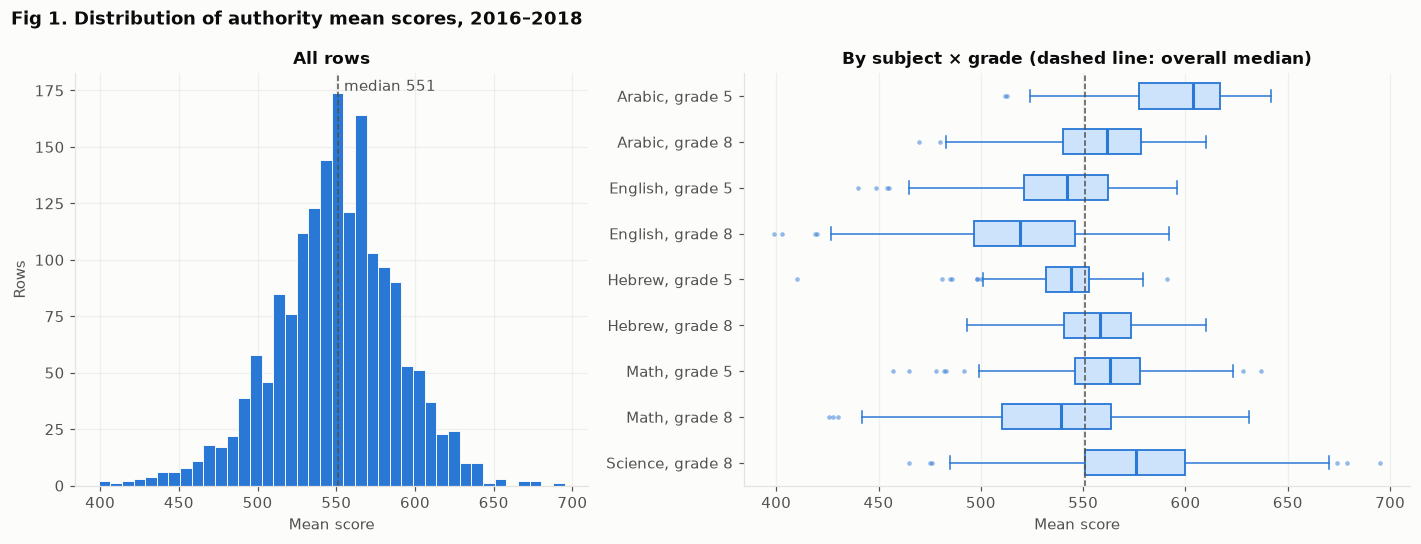

count   mean  median   std    min    max
subject_id shichva                                          
Arabic     5        106.0  593.9   603.5  30.7  512.0  642.0
           8        106.0  555.3   561.5  30.9  470.0  610.0
English    5        185.0  539.5   542.0  31.3  440.0  596.0
           8        268.0  517.9   519.0  37.0  399.0  592.0
Hebrew     5        190.0  540.6   544.0  19.9  410.0  591.0
           8        179.0  557.2   558.0  23.1  493.0  610.0
Math       5        186.0  559.6   563.0  29.5  457.0  637.0
           8        266.0  536.9   539.0  39.5  426.0  631.0
Science    8        263.0  575.2   576.0  37.9  465.0  695.0

In [113]:
fig, (ax_all, ax_grp) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.3]})
overall_median = data["score"].median()

ax_all.hist(data["score"], bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax_all.axvline(overall_median, color=INK_MUTED, linestyle="--", linewidth=1)
ax_all.annotate(f"median {overall_median:.0f}", (overall_median, 1), xycoords=("data", "axes fraction"),
                xytext=(4, -4), textcoords="offset points", va="top", color=INK_MUTED)
ax_all.set(title="All rows", xlabel="Mean score", ylabel="Rows")

ax_grp.boxplot([rows_of(s, g)["score"] for s, g in GROUPS], orientation="horizontal",
               tick_labels=[GROUP_LABELS[k] for k in GROUPS], widths=0.55, **BOX_STYLE)
ax_grp.invert_yaxis()
ax_grp.axvline(overall_median, color=INK_MUTED, linestyle="--", linewidth=1)
ax_grp.set(title="By subject × grade (dashed line: overall median)", xlabel="Mean score")
ax_grp.grid(axis="y", visible=False)
fig.suptitle("Fig 1. Distribution of authority mean scores, 2016–2018", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

score_by_group = (data.groupby(["subject_id", "shichva"])["score"]
                  .describe()[["count", "mean", "50%", "std", "min", "max"]]
                  .rename(columns={"50%": "median"}).rename(index=SUBJECT_NAMES, level=0).round(1))
score_by_group

**Fig 1.** Pooled together, scores look roughly bell-shaped around a median of 551. But the subject × grade
groups sit at very different levels: medians run from 519 (English, grade 8) to 604 (Arabic, grade 5), and
spreads run from an SD of 20 (Hebrew, grade 5) to 40 (Math, grade 8). With one pooled median as the high/low
cut-off, 87% of Arabic grade 5 rows would be "high" and only 18% of English grade 8 rows. The label would
mostly record which test a row is, not how the authority did. So the high/low label has to be set **within each
subject × grade**.

### Score against number of students tested

A mean computed from a handful of students swings much more than one computed from hundreds. To see how far
this goes, we plot score against the number of students tested (log scale), count the small cells, and measure
the spread of scores in each size band. The spread is measured as the standard deviation of each row's distance
from its own subject × grade mean, so the differences in level between subjects don't inflate it.

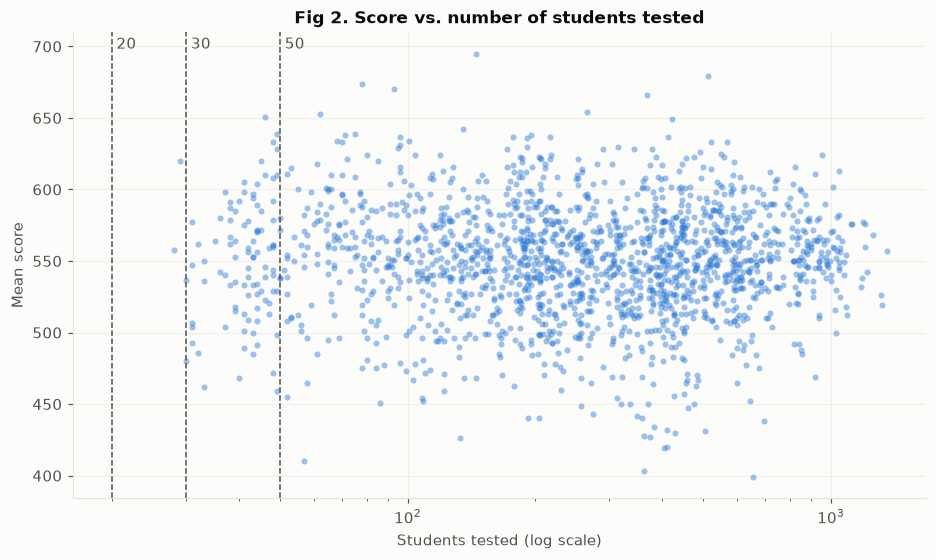

,rows,% of rows,authorities
under 20,0.0,0.0,0.0
under 30,2.0,0.1,2.0
under 50,96.0,5.5,24.0


,rows,SD of distance from subject × grade mean
n_students_tested,,
20–29,2,19.6
30–49,94,35.8
50–99,186,37.2
100–199,381,30.2
200+,1086,32.3


In [114]:
SMALL_CELL_CUTOFFS = [20, 30, 50]
n_tested = data["n_students_tested"]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(n_tested, data["score"], s=16, color=BLUE, alpha=0.45, linewidths=0)
ax.set_xscale("log")
for cutoff in SMALL_CELL_CUTOFFS:
    ax.axvline(cutoff, color=INK_MUTED, linestyle="--", linewidth=1)
    ax.annotate(str(cutoff), (cutoff, 1), xycoords=("data", "axes fraction"), xytext=(3, -3),
                textcoords="offset points", va="top", color=INK_MUTED)
ax.set(xlabel="Students tested (log scale)", ylabel="Mean score",
       title="Fig 2. Score vs. number of students tested")
plt.show()

small_cells = pd.DataFrame({
    f"under {cutoff}": {
        "rows": (n_tested < cutoff).sum(),
        "% of rows": round((n_tested < cutoff).mean() * 100, 1),
        "authorities": data.loc[n_tested < cutoff, "rashut"].nunique(),
    }
    for cutoff in SMALL_CELL_CUTOFFS
}).T
display(small_cells)

distance_from_group_mean = data["score"] - data.groupby(["subject_id", "shichva"])["score"].transform("mean")
size_band = pd.cut(n_tested, [0, 20, 30, 50, 100, 200, np.inf], right=False,
                   labels=["<20", "20–29", "30–49", "50–99", "100–199", "200+"])
distance_from_group_mean.groupby(size_band, observed=True).agg(["count", "std"]).round(1).rename(
    columns={"count": "rows", "std": "SD of distance from subject × grade mean"})

**Fig 2.** Once rows without a score are gone, the very small cells are gone too. No row has under 20 students
tested, 2 rows have under 30, and 96 rows (5.5%, from 24 authorities) have under 50. The Ministry evidently
doesn't publish a score for very small groups (see the next table). There's no clear funnel either: scores in
the 30–49 band spread about as much as in the 200+ band (SD 35.8 vs 32.3 around the subject × grade mean). A
cut-off at 30 would remove only 2 rows, so the small-cell problem is mostly handled by the Ministry's own
suppression. Weighting by `n_students_tested` in the models is still reasonable, but it will matter less than
expected.

### Rows with no score: small samples or one sector?

The 44 rows with no score were already taken out in the cleaning step (`rows_without_score` holds them). Here
we check whether they are random or follow a pattern. We compare the share of missing scores by size band and
by sector, out of all rows before the drop.

In [115]:
before_drop = pd.concat([
    data[["norm_id", "n_students_tested"]].assign(missing_score=False),
    rows_without_score[["norm_id", "n_students_tested"]].assign(missing_score=True),
])
before_size_band = pd.cut(before_drop["n_students_tested"], [0, 20, 30, 50, np.inf], right=False,
                          labels=["<20", "20–29", "30–49", "50+"])

def missing_share(by):
    table = before_drop.groupby(by, observed=True)["missing_score"].agg(rows="size", missing_score="sum")
    table["% missing"] = (table["missing_score"] / table["rows"] * 100).round(1)
    return table

print("By number of students tested:")
display(missing_share(before_size_band))
print("By sector:")
display(missing_share(before_drop["norm_id"].map(SECTOR_NAMES)))

assert data["score"].notna().all(), "the analysis table should have no missing scores"
print(f"Rows with no score dropped: {len(rows_without_score)}; analysis table: {len(data)} rows")

By number of students tested:


,rows,missing_score,% missing
n_students_tested,,,
<20,25,25,100.0
20–29,17,15,88.2
30–49,95,1,1.1
50+,1656,3,0.2


By sector:


,rows,missing_score,% missing
norm_id,,,
Arabic-language,561,4,0.7
Hebrew-language,1025,35,3.4
combined,207,5,2.4


Rows with no score dropped: 44; analysis table: 1749 rows


**Missing scores follow group size, not sector.** All 25 rows with under 20 students tested and 15 of the 17
rows with 20–29 have no score. Above 30 students only 4 of 1,751 rows (0.2%) are missing. The Hebrew-language
sector has a higher missing rate (3.4% vs 0.7%) only because it has more small groups. Every one of its missing
rows has under 30 students tested. So the missing scores are not random: they are the smallest groups, held back
by the Ministry. They can't be filled in and were dropped (44 rows). The cost is that the smallest authorities
are under-represented, which belongs in the limitations.

### Score by socio-economic cluster, per subject × grade

This section checks the relationship the project is built on: do authorities in higher socio-economic clusters
score higher? Each subject × grade gets its own panel, because they sit at different levels (Fig 1). The
correlation in each title says how strongly score moves with the cluster, from 0 for no relationship to 1 for a
perfect one. The gradient itself is already well documented, so we confirm it here as a baseline rather than
present it as a finding of our own.

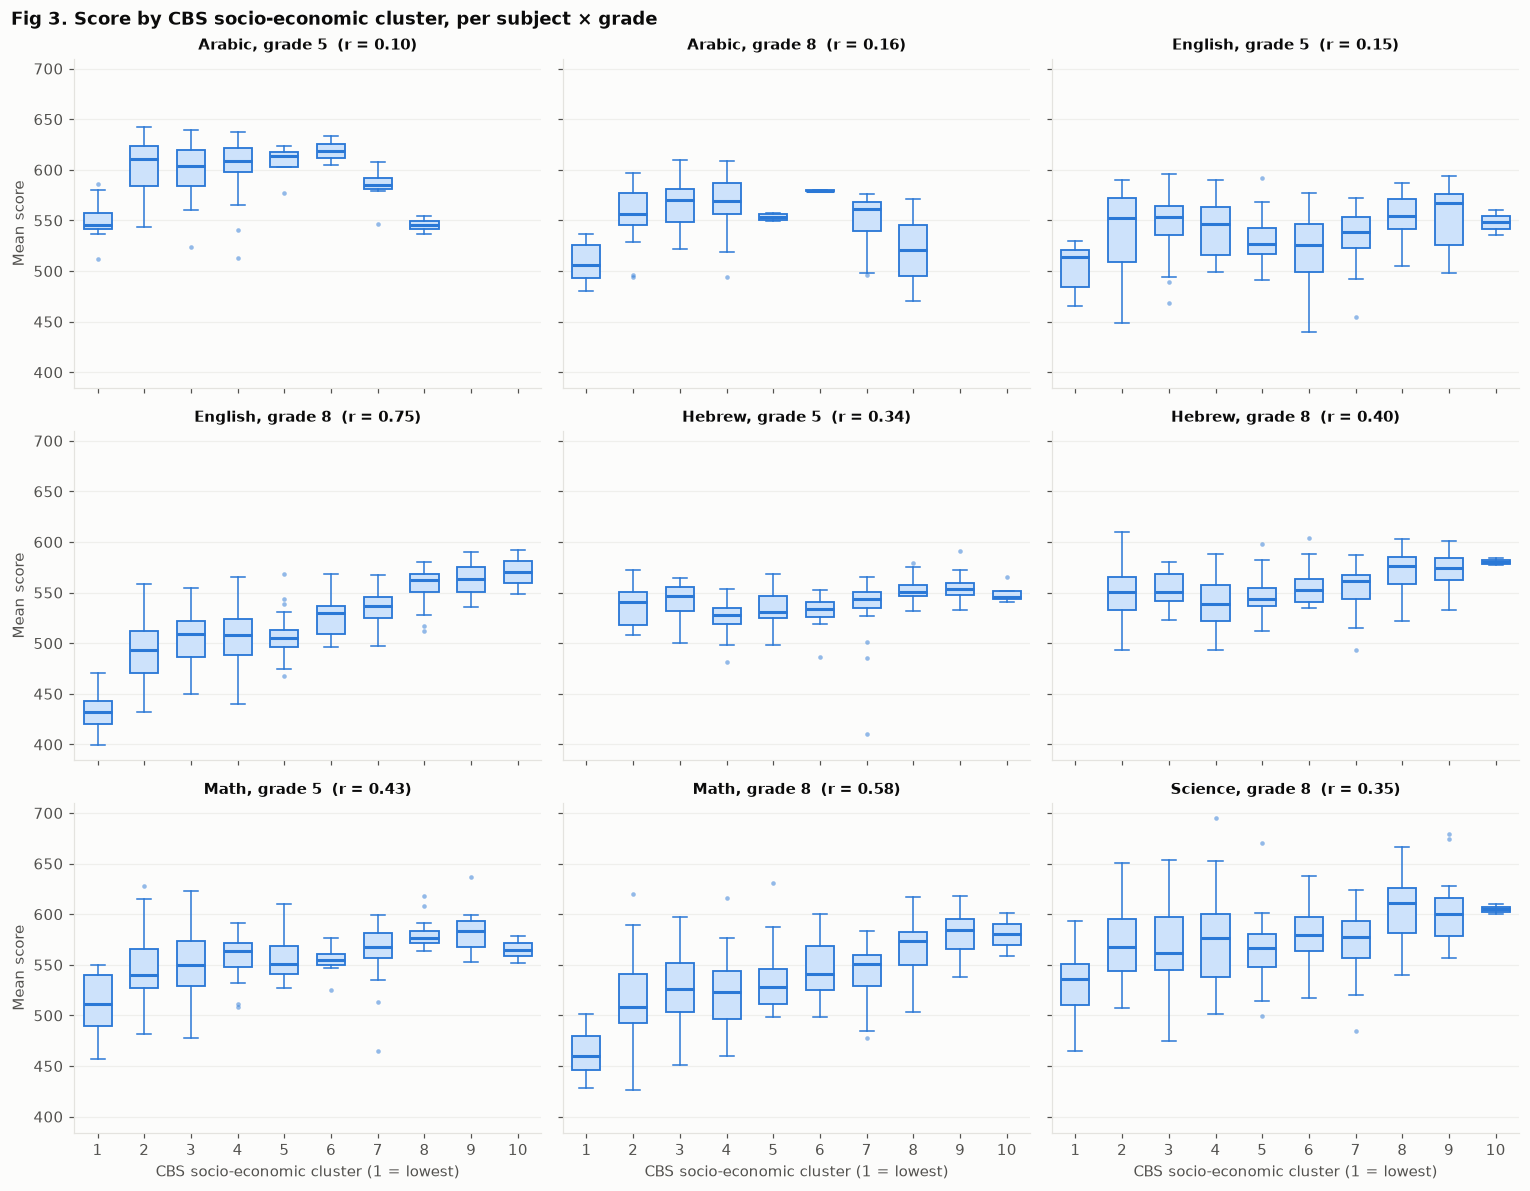

In [116]:
CLUSTERS = range(1, 11)
fig, axes = plt.subplots(3, 3, figsize=(14, 11), sharex=True, sharey=True)

for ax, (subject, grade) in zip(axes.flat, GROUPS):
    rows = rows_of(subject, grade)
    present = [c for c in CLUSTERS if (rows["ses_cluster"] == c).any()]
    ax.boxplot([rows.loc[rows["ses_cluster"] == c, "score"] for c in present], positions=present,
               widths=0.6, **BOX_STYLE)
    correlation = rows["ses_cluster"].corr(rows["score"])
    ax.set_title(f"{GROUP_LABELS[(subject, grade)]}  (r = {correlation:.2f})", fontsize=10)
    ax.set_xticks(list(CLUSTERS), [str(c) for c in CLUSTERS])
    ax.grid(axis="x", visible=False)

for ax in axes[-1]:
    ax.set_xlabel("CBS socio-economic cluster (1 = lowest)")
for ax in axes[:, 0]:
    ax.set_ylabel("Mean score")
fig.suptitle("Fig 3. Score by CBS socio-economic cluster, per subject × grade", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
plt.show()

**Fig 3.** Scores rise with socio-economic cluster in most subject × grade groups. The gradient is strongest in
English grade 8 (r = 0.75) and Math grade 8 (0.58), weaker in Hebrew (0.34 and 0.40) and Math grade 5 (0.43),
and weakest in Arabic grade 5 (0.10) and English grade 5 (0.15). The Arabic panels rise and then fall, which comes from a **sector overlap** rather than
from socio-economic level. Arabic is tested only in Arabic-language schools. Clusters 1–3 are almost all
Arabic-language authorities (cluster 1 is the Negev Bedouin towns), and the few Arabic rows in clusters 7–8 come
from mixed authorities such as Haifa, Tel Aviv-Yafo and Misgav. The same overlap runs through the other subjects:
low clusters are mostly Arabic-language authorities and high clusters mostly Hebrew-language ones. Part of
any "cluster effect" is therefore a sector effect, so sector (`norm_id`) has to be in the models alongside the
index. Clusters 1 and 10 also hold few authorities (9 and 4), so their boxes are based on few points.

# 2. Correlation Analysis

The proposal's second step: measure and visualise the relationship between the continuous socio-economic index
and the score, subject by subject and grade by grade, and check how far the socio-economic variables overlap
with one another.

### Score against the continuous socio-economic index

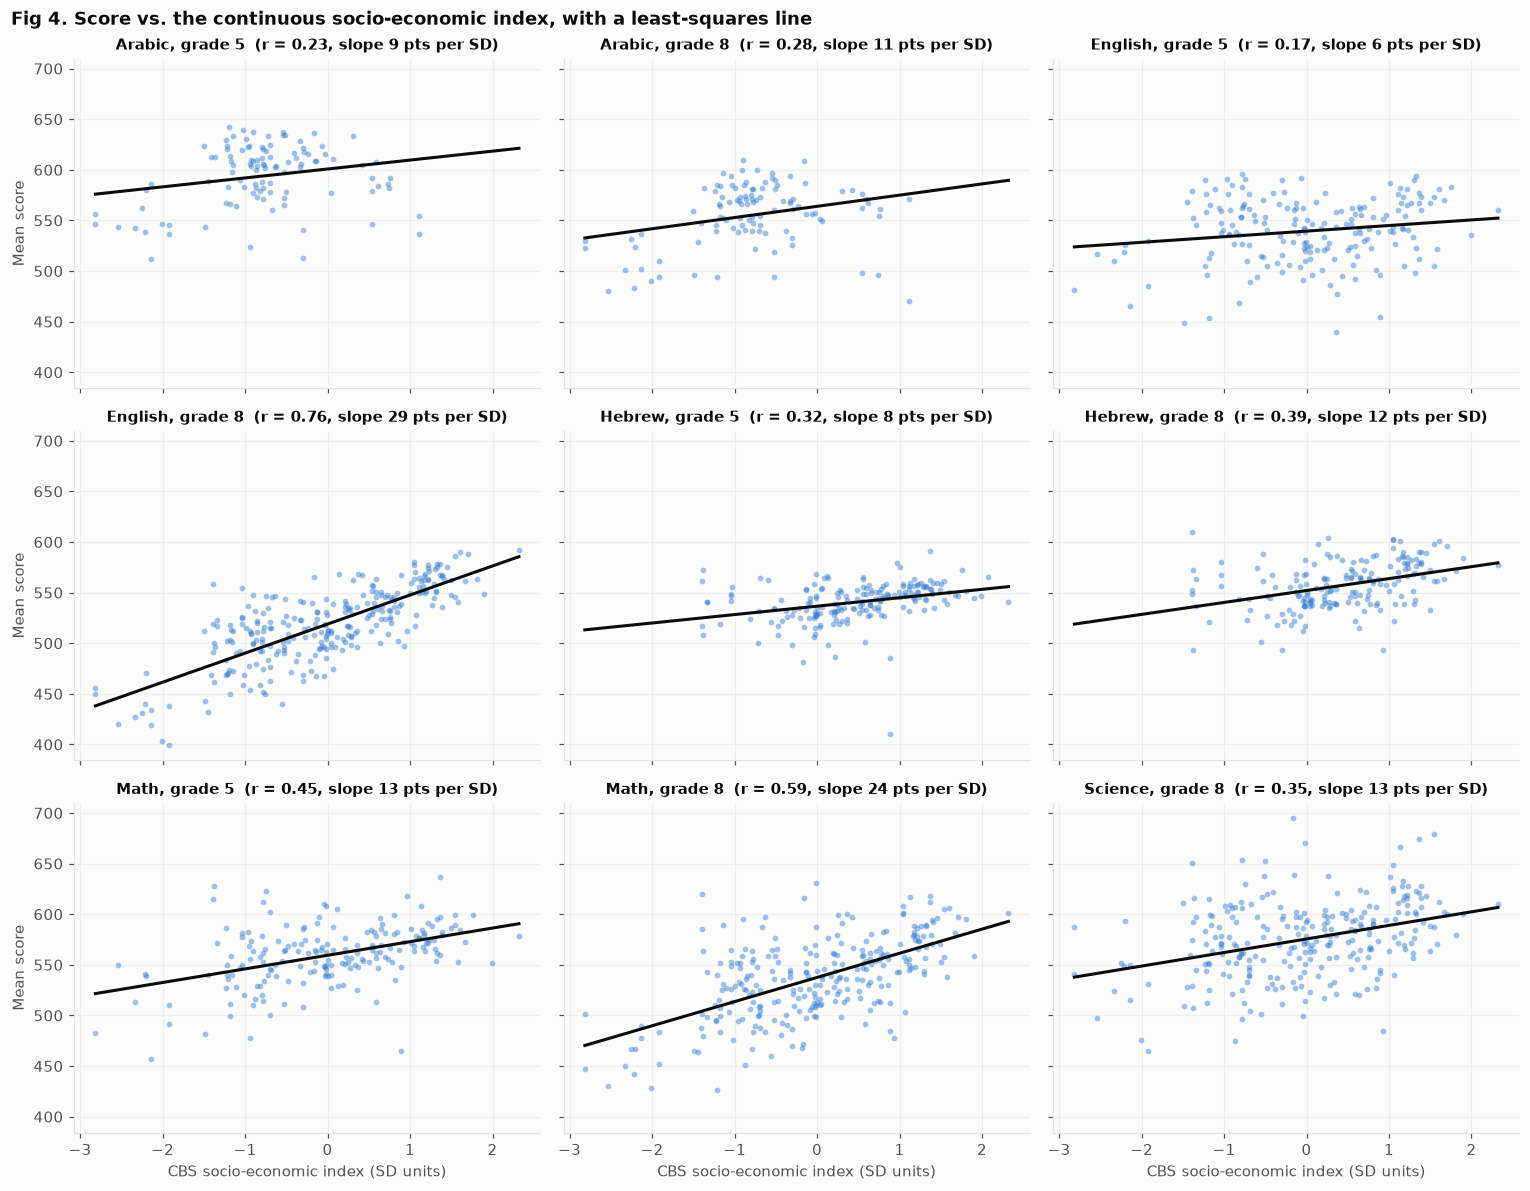

In [117]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11), sharex=True, sharey=True)
index_grid = np.linspace(data["ses_index"].min(), data["ses_index"].max(), 50)

for ax, (subject, grade) in zip(axes.flat, GROUPS):
    rows = rows_of(subject, grade)
    ax.scatter(rows["ses_index"], rows["score"], s=14, color=BLUE, alpha=0.45, linewidths=0)
    slope, intercept = np.polyfit(rows["ses_index"], rows["score"], 1)
    ax.plot(index_grid, intercept + slope * index_grid, color=INK, linewidth=2)
    r = rows["ses_index"].corr(rows["score"])
    ax.set_title(f"{GROUP_LABELS[(subject, grade)]}  (r = {r:.2f}, slope {slope:.0f} pts per SD)", fontsize=10)

for ax in axes[-1]:
    ax.set_xlabel("CBS socio-economic index (SD units)")
for ax in axes[:, 0]:
    ax.set_ylabel("Mean score")
fig.suptitle("Fig 4. Score vs. the continuous socio-economic index, with a least-squares line",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Fig 4.** The continuous index shows the same picture. The relationship is strongest in English grade 8
(r = 0.76, about 29 points per SD of the index) and Math grade 8 (r = 0.59, 24 points), and weak in grade 5 and in
Arabic (r = 0.17–0.28). So the index explains a lot in some tests and little in others. That's why the gaps
between actual and predicted scores, the core of the project, should be computed within subject × grade. Points
far above or below the line at the same index value are the over- and under-performers we're looking for.

### Correlations between the CBS variables

The CBS variables describe authorities, not test rows, so we compute the correlations on one row per
authority. Otherwise authorities with more tested subjects would count more.

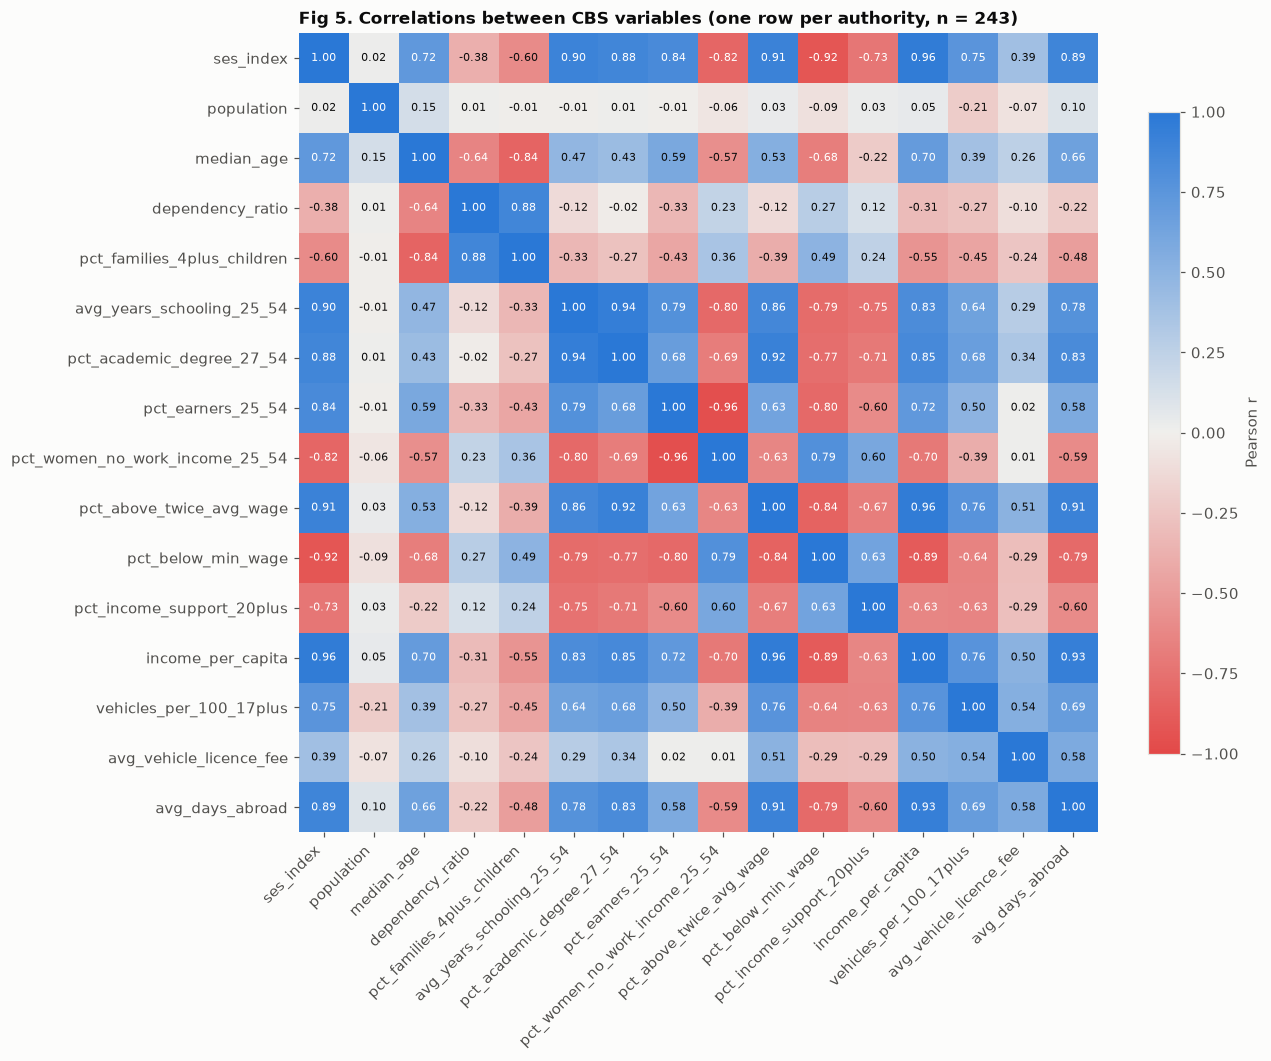

Variable pairs with |r| > 0.8: 23 of 120

Correlation of each variable with ses_index:
income_per_capita                 0.96
pct_below_min_wage               -0.92
pct_above_twice_avg_wage          0.91
avg_years_schooling_25_54         0.90
avg_days_abroad                   0.89
pct_academic_degree_27_54         0.88
pct_earners_25_54                 0.84
pct_women_no_work_income_25_54   -0.82
vehicles_per_100_17plus           0.75
pct_income_support_20plus        -0.73
median_age                        0.72
pct_families_4plus_children      -0.60
avg_vehicle_licence_fee           0.39
dependency_ratio                 -0.38
population                        0.02


In [118]:
CBS_FEATURES = ["ses_index", "population"] + CBS_VARIABLES
cbs_corr = data.drop_duplicates("rashut")[CBS_FEATURES].corr()

diverging = LinearSegmentedColormap.from_list("red_gray_blue", [RED, NEUTRAL, BLUE])
fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(cbs_corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(CBS_FEATURES)), CBS_FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(CBS_FEATURES)), CBS_FEATURES)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
for i in range(len(CBS_FEATURES)):
    for j in range(len(CBS_FEATURES)):
        r = cbs_corr.iat[i, j]
        ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(r) > 0.6 else INK)
fig.colorbar(image, ax=ax, shrink=0.75, label="Pearson r")
ax.set_title(f"Fig 5. Correlations between CBS variables (one row per authority, n = {data['rashut'].nunique()})",
             loc="left")
fig.tight_layout()
plt.show()

upper = cbs_corr.where(np.triu(np.ones(cbs_corr.shape, dtype=bool), k=1)).stack().dropna()
print(f"Variable pairs with |r| > 0.8: {(upper.abs() > 0.8).sum()} of {len(upper)}")
print()
print("Correlation of each variable with ses_index:")
print(cbs_corr["ses_index"].drop("ses_index").sort_values(key=abs, ascending=False).round(2).to_string())

**Fig 5.** The CBS variables are strongly correlated with each other. `ses_index` correlates above 0.8 with
eight of them, led by income per capita (0.96), the share earning below minimum wage (−0.92) and the share earning
above twice the average wage (0.91). The schooling and degree variables (0.90 and 0.88) are among the inputs the
CBS uses to build the index, so they partly *are* the index. Two consequences follow. A linear model that uses
`ses_index` and these variables together will have unstable coefficients. And Random Forest feature importances
will be split arbitrarily between near-duplicates, so they can't be read as independent effects. `population`
is the one variable unrelated to the index (r = 0.02), and `avg_vehicle_licence_fee` and `dependency_ratio` are
only weakly related.

# 3. Data Splitting

The proposal's third step: training, validation and test sets. The proposal asked for 50 / 30 / 20. We split by
authority rather than by row, which the feedback required, and stratify by cluster so every cluster appears in
all three sets.

## Model Building

## Train / validation / test split by authority

Our rows are not independent. The analysis table has 1,749 rows from only 243 authorities, and each authority
appears up to 25 times (once per year, grade and subject). If we split by row, the same authority would sit in
both the training and the test set. A model could then learn that authority's typical score and look accurate on
the test set without having learned anything that carries over to a new authority. So we split by **authority**
(`rashut`): every row of an authority goes to the same set.

We use `GroupShuffleSplit` with `rashut` as the group, holding out about 30% of the authorities for test and 20%
for validation, which leaves about 50% for training. Cluster 10 has only 4 authorities and cluster 1 has 9, so one
split over the whole table can easily leave a cluster out of the validation or test set. We therefore run the split
**inside each cluster** and combine the parts. That stratifies by cluster: every cluster appears in all three sets.
Because authorities contribute different numbers of rows, the shares by row will differ from the shares by
authority, so we report both.

In [119]:
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, train_test_split

TEST_SHARE, VAL_SHARE = 0.3, 0.2  # shares of authorities; training gets the remaining ~50%

def hold_out_authorities(rows, n_out, seed=RANDOM_STATE):
    # GroupShuffleSplit with rashut as the group: n_out whole authorities go to the second part
    splitter = GroupShuffleSplit(n_splits=1, test_size=n_out, random_state=seed)
    keep, out = next(splitter.split(rows, groups=rows["rashut"]))
    return rows.iloc[keep], rows.iloc[out]

# Split each cluster separately so that every cluster, even cluster 10 with 4 authorities, lands in all three sets
parts = {"train": [], "validation": [], "test": []}
for cluster, rows in data.groupby("ses_cluster"):
    n_authorities = rows["rashut"].nunique()
    rest, test = hold_out_authorities(rows, max(1, round(TEST_SHARE * n_authorities)))
    train, validation = hold_out_authorities(rest, max(1, round(VAL_SHARE * n_authorities)))
    for name, part in [("train", train), ("validation", validation), ("test", test)]:
        parts[name].append(part)

SPLITS = {name: pd.concat(part_list).sort_index() for name, part_list in parts.items()}
train_set, val_set, test_set = SPLITS["train"], SPLITS["validation"], SPLITS["test"]

# Fail if an authority is in two sets, or if a row was lost or duplicated
authorities_in = {name: set(rows["rashut"]) for name, rows in SPLITS.items()}
shared = ((authorities_in["train"] & authorities_in["validation"]) | (authorities_in["train"] & authorities_in["test"])
          | (authorities_in["validation"] & authorities_in["test"]))
assert not shared, f"Authorities in more than one set: {sorted(shared)}"
assert sorted(np.concatenate([rows.index for rows in SPLITS.values()])) == sorted(data.index), "rows lost or duplicated"
print("No authority appears in more than one set.")

split_sizes = pd.DataFrame({
    name: {
        "rows": len(rows),
        "% of rows": round(100 * len(rows) / len(data), 1),
        "authorities": rows["rashut"].nunique(),
        "% of authorities": round(100 * rows["rashut"].nunique() / data["rashut"].nunique(), 1),
        "clusters": rows["ses_cluster"].nunique(),
    }
    for name, rows in SPLITS.items()
}).T.astype({"rows": int, "authorities": int, "clusters": int})
display(split_sizes)

authority_split = pd.concat([rows.drop_duplicates("rashut").assign(split=name) for name, rows in SPLITS.items()])
print("Authorities per cluster in each set:")
display(pd.crosstab(authority_split["ses_cluster"], authority_split["split"], margins=True, margins_name="total")
        [["train", "validation", "test", "total"]])

No authority appears in more than one set.


,rows,% of rows,authorities,% of authorities,clusters
train,840,48.0,121,49.8,10
validation,362,20.7,48,19.8,10
test,547,31.3,74,30.5,10


Authorities per cluster in each set:


split,train,validation,test,total
ses_cluster,,,,
1,4,2,3,9
2,11,4,7,22
3,22,9,13,44
4,16,6,10,32
5,14,5,8,27
6,11,4,7,22
7,19,8,11,38
8,9,4,6,19
9,13,5,8,26


**Table 4.** By authority the split is 50 / 20 / 30 (121 / 48 / 74 authorities). By row it comes out at
48 / 21 / 31 (840 / 362 / 547 rows), close to the target because the per-cluster splits even out the differences in
rows per authority. No authority is in two sets, and all 10 clusters appear in each set, including cluster 10
(2 / 1 / 1 authorities) and cluster 1 (4 / 2 / 3).

To check that stratifying was needed, we repeat the same 50/30/20 grouped split over the whole table, without
splitting by cluster first, for 1,000 different seeds and count how often a set ends up missing a cluster.

In [120]:
def misses_a_cluster(seed):
    rest, test = hold_out_authorities(data, TEST_SHARE, seed)
    train, validation = hold_out_authorities(rest, VAL_SHARE / (1 - TEST_SHARE), seed)
    return any(rows["ses_cluster"].nunique() < data["ses_cluster"].nunique() for rows in (train, validation, test))

N_SEEDS = 1000
missed = sum(misses_a_cluster(seed) for seed in range(N_SEEDS))
print(f"Unstratified grouped split: at least one set is missing a cluster in {missed} of {N_SEEDS} seeds "
      f"({100 * missed / N_SEEDS:.0f}%)")

Unstratified grouped split: at least one set is missing a cluster in 688 of 1000 seeds (69%)


Without stratifying, 69% of seeds leave at least one cluster out of a set, almost always cluster 10 or 1. With 4
authorities in cluster 10, a 20% validation set gets fewer than one of them on average. Splitting inside each
cluster removes this risk.

### Folds for tuning
Hyperparame
ters will be tuned by cross-validation on the training set. The folds have to respect authorities too,
otherwise the same leak comes back inside tuning. `GroupKFold` with `rashut` as the group puts each authority in
exactly one fold. `TUNING_CV` and `train_groups` are passed to `GridSearchCV` later (`cv=TUNING_CV`,
`groups=train_groups`). We use 5 fold because it's the conventional default.

In [121]:
TUNING_CV = GroupKFold(n_splits=5)
train_groups = train_set["rashut"]

fold_sizes = {}
for fold, (fit_idx, check_idx) in enumerate(TUNING_CV.split(train_set, groups=train_groups), start=1):
    fit_rows, check_rows = train_set.iloc[fit_idx], train_set.iloc[check_idx]
    assert not set(fit_rows["rashut"]) & set(check_rows["rashut"]), f"fold {fold} shares an authority"
    fold_sizes[f"fold {fold}"] = {
        "rows": len(check_rows),
        "authorities": check_rows["rashut"].nunique(),
        "clusters": check_rows["ses_cluster"].nunique(),
    }

print("No authority is in both the fitting and the checking part of any fold.")
print("Held-out part of each fold:")
display(pd.DataFrame(fold_sizes).T)

No authority is in both the fitting and the checking part of any fold.
Held-out part of each fold:


,rows,authorities,clusters
fold 1,169,24,8
fold 2,168,24,8
fold 3,168,25,9
fold 4,167,24,7
fold 5,168,24,8


Each fold holds out about 24 authorities (167–169 rows), and no authority is on both sides of a fold. Each held-out
fold covers 7 to 9 of the 10 clusters. That can't be fixed: the training set has only 2 authorities from cluster 10
and 4 from cluster 1, so they can't reach all 5 folds. The validation and test sets do cover every cluster, and
those are where results are reported.

### For comparison: a plain split by row

We also run the split the usual way once, by row with `train_test_split`, in the same 50/30/20 shares. We count how
many authorities end up in more than one set, and test the memorising shortcut directly: predict each test row
from the same authority's average in the training set, without any socio-economic variable. Scores are first
standardized within each subject × grade × year (using training-set means and SDs) so that rows from different
tests are comparable. Under the grouped split this shortcut is impossible, because no test authority has rows in
the training set.

In [122]:
row_rest, row_test = train_test_split(data, test_size=TEST_SHARE, random_state=RANDOM_STATE)
row_train, row_val = train_test_split(row_rest, test_size=VAL_SHARE / (1 - TEST_SHARE), random_state=RANDOM_STATE)
ROW_SPLITS = {"train": row_train, "validation": row_val, "test": row_test}

sets_per_authority = pd.concat([rows[["rashut"]].assign(split=name) for name, rows in ROW_SPLITS.items()]) \
    .groupby("rashut")["split"].nunique()
test_rows_seen = row_test["rashut"].isin(row_train["rashut"]).mean()
print(f"Row split: {(sets_per_authority > 1).sum()} of {len(sets_per_authority)} authorities appear in more than one set")
print(f"Row split: {100 * test_rows_seen:.0f}% of test rows belong to an authority that is also in the training set")

def standardized(rows, reference):
    # z-score within subject × grade × year, using the reference (training) rows' mean and SD
    keys = ["subject_id", "shichva", "year"]
    stats = reference.groupby(keys)["score"].agg(["mean", "std"])
    joined = rows.join(stats, on=keys)
    return (joined["score"] - joined["mean"]) / joined["std"]

train_z = standardized(row_train, row_train)
authority_mean_z = train_z.groupby(row_train["rashut"]).mean()
test_z = standardized(row_test, row_train)
predicted_z = row_test["rashut"].map(authority_mean_z).fillna(0)  # unseen authority: predict the average

r2 = 1 - ((test_z - predicted_z) ** 2).sum() / ((test_z - test_z.mean()) ** 2).sum()
print(f"Row split, predicting each test row from its authority's training average: R² = {r2:.2f}")
print(f"Grouped split: {test_set['rashut'].isin(train_set['rashut']).sum()} test rows belong to a training authority, "
      "so this shortcut is not available")

Row split: 236 of 243 authorities appear in more than one set
Row split: 97% of test rows belong to an authority that is also in the training set
Row split, predicting each test row from its authority's training average: R² = 0.30
Grouped split: 0 test rows belong to a training authority, so this shortcut is not available


**The difference.** In the plain row split, 236 of the 243 authorities land in more than one set, and 97% of test
rows belong to an authority the model has already seen in training. Predicting each test row from nothing but its
authority's training average already gives R² = 0.30, without a single socio-economic variable. In a row split, part of
any model's test accuracy would be this memorising, not a relationship that carries over to a new authority. In the
grouped split no test authority appears in training, so the shortcut isn't there. Later, the models will be scored
both ways. To show how much the row split flatters them. The grouped numbers are the ones we report.

# 4. Supervised Learning: Regression and Classification

The proposal's fifth step, brought forward. **The proposal listed clustering before the supervised models; the
two are swapped here** because the clustering in section 5 uses the gaps that the regression produces, so it
cannot run first.

- **4.1** Regression: Random Forest and Linear Regression against two baselines, as the proposal set out.
- **4.2** Classification: the score turned into a High / Low label, Random Forest against Logistic Regression.
- **4.3** Over- and under-performing authorities. Not in the proposal: this came out of the feedback, which
  asked us to lead with the authorities that depart from what their cluster predicts. It belongs here because
  it is built from what the regression misses.

## 4.1 Regression: predicting the score

## Predicting the score

How well can an authority's score be predicted? This matters because the over- and under-performers are
defined as the authorities a model *misses*. If the model predicted badly, every authority would look like an
outlier.

**Features (20).** 16 numbers describing the authority — `ses_index`, `population` and the 14 CBS variables —
plus 4 labels describing the test: grade, subject, sector and year. The labels are needed because scores sit at
different levels per subject × grade (Fig 1), sector overlaps with cluster (Fig 3), and scores drift between
2016 and 2018.

Left out: `ses_cluster` (the same measurement as `ses_index`, Fig 5), the test-administration columns
(`n_students_tested` is used as the row weight instead), and `rashut` — feeding in the authority id would be
the memorising shortcut the grouped split just removed.

**Missing values.** The 3 authorities with suppressed CBS variables are filled with the median *inside the
pipeline*, so the median comes from the training rows only. Dropping them would thin out the upper clusters.

**Protocol.** Fit on training, compare on validation, open the test set once at the end for the winner.

In [123]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERIC_FEATURES = ["ses_index", "population"] + CBS_VARIABLES
CATEGORICAL_FEATURES = ["shichva", "year"]                       # still encoded inside the pipeline
DUMMY_FEATURES = SUBJECT_DUMMIES + SECTOR_DUMMIES                # already encoded during cleaning
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES + DUMMY_FEATURES
TARGET, WEIGHT = "score", "n_students_tested"

def features_target_weight(rows):
    return rows[FEATURES], rows[TARGET], rows[WEIGHT].to_numpy(float)

X_train, y_train, w_train = features_target_weight(train_set)
X_val, y_val, w_val = features_target_weight(val_set)
X_test, y_test, w_test = features_target_weight(test_set)

def make_pipeline(model, drop_first):
    # Imputing and scaling learn their numbers inside the pipeline, so in cross-validation they only
    # ever see the fitting fold. The median fills the suppressed CBS variables.
    # drop_first removes one column per categorical variable: needed for the linear and logistic models,
    # which would otherwise have a redundant column per variable alongside the intercept. Subject and
    # sector were encoded during cleaning, so for them we drop the first column by selecting a subset.
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    encoder = lambda: OneHotEncoder(drop="first" if drop_first else None, handle_unknown="ignore")
    dummies = (SUBJECT_DUMMIES[1:] + SECTOR_DUMMIES[1:]) if drop_first else DUMMY_FEATURES
    # Grade and year are listed either side of the pre-encoded block so that the columns reach the
    # model in the same order as before subject and sector were moved into the cleaning step
    preprocess = ColumnTransformer([("num", numeric, NUMERIC_FEATURES),
                                    ("grade", encoder(), ["shichva"]),
                                    ("already_encoded", "passthrough", dummies),
                                    ("year", encoder(), ["year"])])
    return Pipeline([("prep", preprocess), ("model", model)])

# Every model's validation numbers land here, so they can be compared in one table
results, val_predictions = [], {}

def record(name, fitted_on, y_true, prediction, weights):
    results.append({
        "model": name,
        "fitted on": fitted_on,
        "R2": r2_score(y_true, prediction),
        "RMSE": mean_squared_error(y_true, prediction) ** 0.5,
        "MAE": mean_absolute_error(y_true, prediction),
        "R2 weighted": r2_score(y_true, prediction, sample_weight=weights),
    })
    return prediction

def results_table():
    return pd.DataFrame(results).set_index(["model", "fitted on"]).round(3)

print(f"{len(FEATURES)} feature columns: {len(NUMERIC_FEATURES)} numeric, "
      f"{len(CATEGORICAL_FEATURES)} encoded in the pipeline, {len(DUMMY_FEATURES)} encoded during cleaning")
print(f"Rows - train {len(X_train)}, validation {len(X_val)}, test {len(X_test)}")
print("Rows whose CBS variables are suppressed (median-imputed in the pipeline):",
      {name: int(X[CBS_VARIABLES].isna().any(axis=1).sum())
       for name, X in [("train", X_train), ("validation", X_val), ("test", X_test)]})

26 feature columns: 16 numeric, 2 encoded in the pipeline, 8 encoded during cleaning
Rows - train 840, validation 362, test 547
Rows whose CBS variables are suppressed (median-imputed in the pipeline): {'train': 1, 'validation': 1, 'test': 4}


### Two baselines

To judge a model we first need to know what counts as doing well.

1. **Overall mean** — always guess the average training score. This is the floor. Its R² is not exactly 0
   because it uses the *training* mean, not the validation mean.
2. **Subject × grade mean** — guess the average for that subject and grade, and nothing else. This is the one
   that matters: Fig 1 showed most of the variation in `score` is just the difference between tests, so a model
   that cannot beat it has learned nothing about authorities.

In [124]:
overall_mean = y_train.mean()
GROUP_KEYS = ["subject_id", "shichva"]
group_mean = train_set.groupby(GROUP_KEYS)[TARGET].mean()

def predict_overall_mean(rows):
    return np.full(len(rows), overall_mean)

def predict_group_mean(rows):
    # Takes the row frame rather than the feature matrix, because subject_id is a grouping column
    # now rather than a model input. A subject x grade missing from training falls back to the overall mean.
    return (rows.join(group_mean.rename("group_mean"), on=GROUP_KEYS)["group_mean"]
            .fillna(overall_mean).to_numpy())

record("Baseline: overall mean", "-", y_val, predict_overall_mean(val_set), w_val)
record("Baseline: subject x grade mean", "-", y_val, predict_group_mean(val_set), w_val)

print(f"Overall training mean: {overall_mean:.1f} points")
print("Training mean per subject x grade:")
display(group_mean.rename(index=SUBJECT_NAMES, level=0).round(1).to_frame("mean score"))
results_table()

Overall training mean: 549.7 points
Training mean per subject x grade:


mean score
subject_id shichva            
Arabic     5             592.8
           8             553.7
English    5             539.9
           8             518.2
Hebrew     5             540.4
           8             558.9
Math       5             559.3
           8             538.0
Science    8             575.7

,,R2,RMSE,MAE,R2 weighted
model,fitted on,,,,
Baseline: overall mean,-,-0.017,40.248,31.067,-0.012
Baseline: subject x grade mean,-,0.297,33.458,25.978,0.325


**The bar to clear.** Guessing the overall mean gives R² = −0.02 and misses by 31 points on average. Knowing
only the subject and grade raises R² to **0.30** and brings the miss down to 26 points. So about a third of the
variation is the difference between tests. That 0.30 is the number the real models have to beat.

### Linear regression

`LinearRegression` on the 16 numeric features plus dummies for grade, subject, sector and year. The features
are on very different scales (`population` in people, `ses_index` in SD units), so they need the
`StandardScaler` — and because it sits inside the pipeline, it learns its means and SDs from training rows only.

We fit it twice: once with every row counting equally, once **weighted by `n_students_tested`**, so a score
from 1,000 students counts more than one from 20. `R² weighted` applies the weights to the scoring as well.

We do not read the coefficients. Fig 5 showed `ses_index` correlates above 0.8 with eight of the CBS variables,
which makes them unstable.

In [125]:
for fitted_on, weights in [("unweighted", None), ("weighted by students tested", w_train)]:
    linear = make_pipeline(LinearRegression(), drop_first=True)
    linear.fit(X_train, y_train, model__sample_weight=weights)
    prediction = record("Linear regression", fitted_on, y_val, linear.predict(X_val), w_val)
    if weights is None:
        val_predictions["Linear regression"] = prediction
        linear_model = linear

print("Columns after preprocessing:", linear_model[:-1].transform(X_train).shape[1])
results_table()

Columns after preprocessing: 25


R2    RMSE  \
model                          fitted on                                    
Baseline: overall mean         -                           -0.017  40.248   
Baseline: subject x grade mean -                            0.297  33.458   
Linear regression              unweighted                   0.364  31.834   
                               weighted by students tested  0.271  34.060   

                                                               MAE  \
model                          fitted on                             
Baseline: overall mean         -                            31.067   
Baseline: subject x grade mean -                            25.978   
Linear regression              unweighted                   24.589   
                               weighted by students tested  26.039   

                                                            R2 weighted  
model                          fitted on                                 
Baseline: overall mean         -                                 -0.012  
Baseline: subject x grade mean -                                  0.325  
Linear regression              unweighted                         0.357  
                               weighted by students tested        0.242

**Result.** Unweighted, R² = 0.364 against the baseline's 0.297 — a real but modest gain. The 16
socio-economic variables buy about 7 points of R² and take the average miss from 26.0 to 24.6 points.

Weighting makes it **worse** (0.271, below the baseline). It pulls the fit towards the large authorities, and
there are few of them. It is worse on the weighted scoring too (0.242 vs 0.357), so this is not a scoring
artefact.

### Random forest

A forest can catch interactions the linear model cannot — for example that the index matters far more in
English grade 8 than in Arabic grade 5 (Fig 4).

Tuning has to respect authorities for the same reason the split does: with ordinary K-fold an authority would
land on both sides of a fold and the scores would be inflated. So `GridSearchCV` gets `TUNING_CV`
(`GroupKFold(5)` on `rashut`, cell 66) and `train_groups`.

The grid covers the three settings that control overfitting: tree depth, minimum rows per leaf, and features
per split. `n_estimators` is fixed at 400 rather than tuned — more trees only cost time.

In [126]:
PARAM_GRID = {
    "model__max_depth": [None, 8, 16],
    "model__min_samples_leaf": [1, 3, 10],
    "model__max_features": ["sqrt", 0.3, 1.0],
}

rf_search = {}
for fitted_on, weights in [("unweighted", None), ("weighted by students tested", w_train)]:
    forest = RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1)
    search = GridSearchCV(make_pipeline(forest, drop_first=False), PARAM_GRID,
                          cv=TUNING_CV, scoring="r2")
    fit_params = {"groups": train_groups}
    if weights is not None:
        fit_params["model__sample_weight"] = weights
    search.fit(X_train, y_train, **fit_params)
    rf_search[fitted_on] = search

tuning = pd.DataFrame({
    fitted_on: {**{key.removeprefix("model__"): str(value) for key, value in search.best_params_.items()},
                "CV R2 (best)": round(search.best_score_, 3),
                "CV R2 (worst in grid)": round(search.cv_results_["mean_test_score"].min(), 3)}
    for fitted_on, search in rf_search.items()
}).T
display(tuning)

,max_depth,max_features,min_samples_leaf,CV R2 (best),CV R2 (worst in grid)
unweighted,None,sqrt,1,0.523,0.405
weighted by students tested,16,1.0,1,0.529,0.379


**What tuning bought.** Across the 27 settings the grouped-CV R² runs from 0.405 to 0.523, so the choice is
worth about 12 points. The winner is an unrestricted forest that looks at only `sqrt` of the features at each
split. That is the usual answer when features are correlated (Fig 5): it stops every tree from reaching for
`income_per_capita` first, so the trees end up different from each other. Sklearn's default (all features)
scores 0.500.

In [127]:
for fitted_on, search in rf_search.items():
    prediction = record("Random forest", fitted_on, y_val, search.best_estimator_.predict(X_val), w_val)
    if fitted_on == "unweighted":
        val_predictions["Random forest"] = prediction

results_table()

R2    RMSE  \
model                          fitted on                                    
Baseline: overall mean         -                           -0.017  40.248   
Baseline: subject x grade mean -                            0.297  33.458   
Linear regression              unweighted                   0.364  31.834   
                               weighted by students tested  0.271  34.060   
Random forest                  unweighted                   0.463  29.242   
                               weighted by students tested  0.413  30.580   

                                                               MAE  \
model                          fitted on                             
Baseline: overall mean         -                            31.067   
Baseline: subject x grade mean -                            25.978   
Linear regression              unweighted                   24.589   
                               weighted by students tested  26.039   
Random forest                  unweighted                   22.020   
                               weighted by students tested  22.655   

                                                            R2 weighted  
model                          fitted on                                 
Baseline: overall mean         -                                 -0.012  
Baseline: subject x grade mean -                                  0.325  
Linear regression              unweighted                         0.357  
                               weighted by students tested        0.242  
Random forest                  unweighted                         0.507  
                               weighted by students tested        0.455

**Table 5. Validation results.** The ranking is the same on all four measures:

| | R² | RMSE | MAE |
|---|---|---|---|
| Overall mean | −0.017 | 40.2 | 31.1 |
| Subject × grade mean | 0.297 | 33.5 | 26.0 |
| Linear regression | 0.364 | 31.8 | 24.6 |
| **Random forest** | **0.463** | **29.2** | **22.0** |

The forest wins: R² = 0.463, an average miss of 22.0 points. It removes about a quarter of the variation the
subject × grade baseline left unexplained, and beats the linear model by 10 points of R² — so the relationship
bends and interacts rather than running straight.

**Weighting does not help either model** (forest 0.463 → 0.413, linear 0.364 → 0.271). It wins only in
cross-validation (0.529 vs 0.523), and that reverses on held-out authorities, so it is noise. This is what
Fig 2 predicted: the Ministry already suppresses very small groups, so there was little instability left to
fix. We carry the **unweighted forest** forward.

### Residuals

R² says how much a model misses; the residuals say *where*. That matters here because the residuals are the
raw material of the main question — an authority scoring far above its prediction is what we mean by an
over-performer. First we have to check they are noise, not a pattern the model missed.

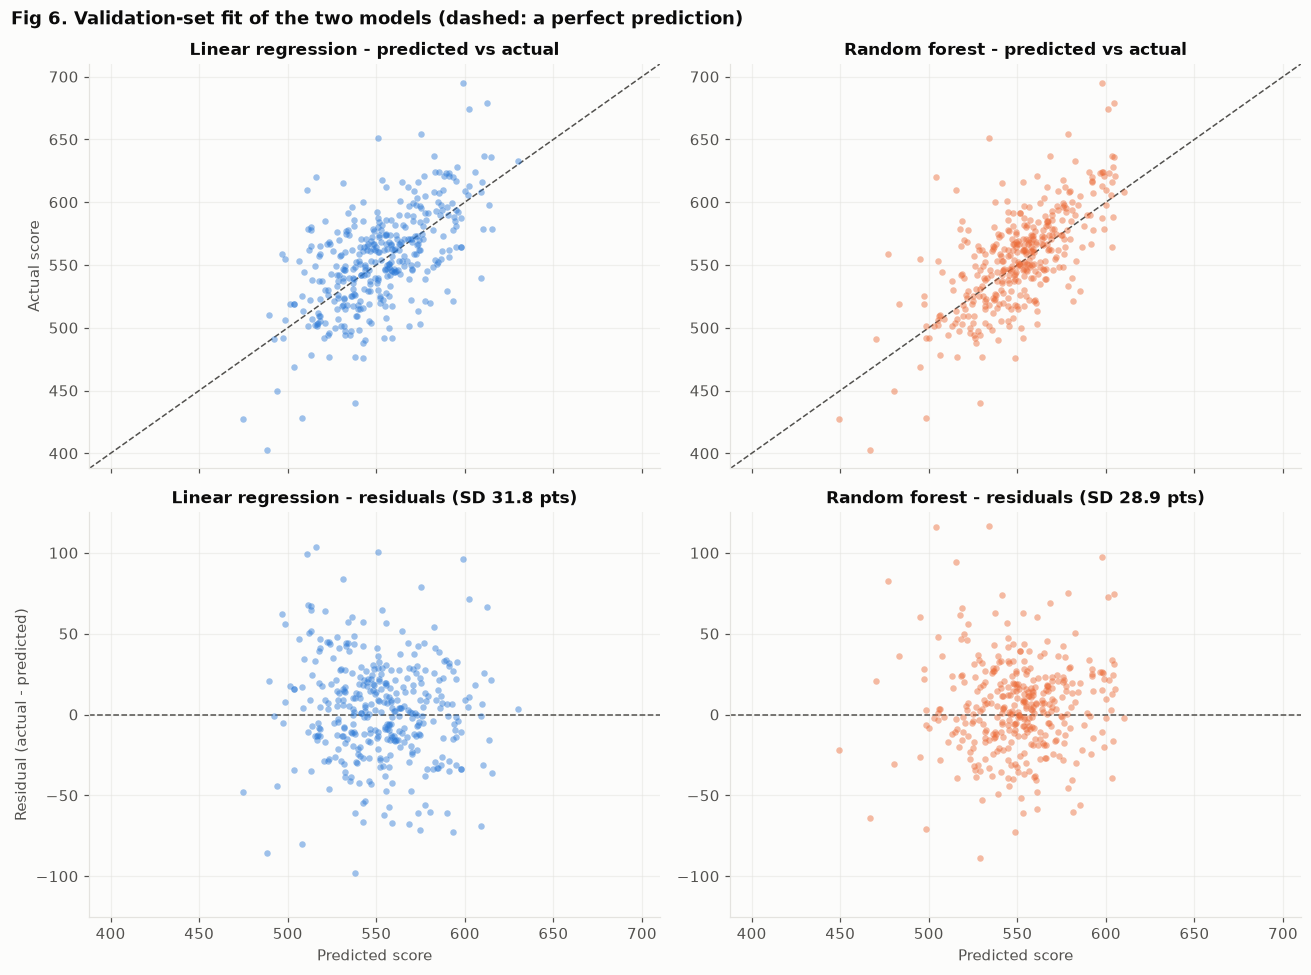

Actual scores span 403-695 points; forest predictions span 449-610


In [128]:
# Categorical slot 2 of the same palette, for the second model
ORANGE = "#eb6834"
MODEL_COLOURS = {"Linear regression": BLUE, "Random forest": ORANGE}

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex="col")
score_limits = (min(y_val.min(), *(p.min() for p in val_predictions.values())) - 15,
                max(y_val.max(), *(p.max() for p in val_predictions.values())) + 15)
residual_limits = (-125, 125)

for column, (name, prediction) in enumerate(val_predictions.items()):
    colour = MODEL_COLOURS[name]
    residual = y_val - prediction

    ax = axes[0, column]
    ax.plot(score_limits, score_limits, color=INK_MUTED, linestyle="--", linewidth=1, zorder=1)
    ax.scatter(prediction, y_val, s=18, color=colour, alpha=0.45, linewidths=0, zorder=2)
    ax.set(xlim=score_limits, ylim=score_limits, title=f"{name} - predicted vs actual",
           ylabel="Actual score" if column == 0 else "")

    ax = axes[1, column]
    ax.axhline(0, color=INK_MUTED, linestyle="--", linewidth=1, zorder=1)
    ax.scatter(prediction, residual, s=18, color=colour, alpha=0.45, linewidths=0, zorder=2)
    ax.set(xlim=score_limits, ylim=residual_limits, xlabel="Predicted score",
           title=f"{name} - residuals (SD {residual.std():.1f} pts)",
           ylabel="Residual (actual - predicted)" if column == 0 else "")

fig.suptitle("Fig 6. Validation-set fit of the two models (dashed: a perfect prediction)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

print(f"Actual scores span {y_val.min():.0f}-{y_val.max():.0f} points; "
      f"forest predictions span {val_predictions['Random forest'].min():.0f}-"
      f"{val_predictions['Random forest'].max():.0f}")

**Fig 6.** Both clouds sit around the diagonal with no bend or funnel: the spread is about the same at a
predicted 500 as at 600, so neither model is systematically wrong at one end. The forest's cloud is tighter
(residual SD 28.9 vs 31.8 points).

The flaw in both is **compression**: actual scores run 403–695, but the forest only ever predicts 449–610. This
is ordinary regression towards the mean — at R² ≈ 0.46 a model keeps its average error down by not committing
to extremes. It matters for the next step: the biggest residuals will tend to belong to authorities with
genuinely extreme scores, so the over/under-performer list means "further from prediction than most", not a
ranking of merit.

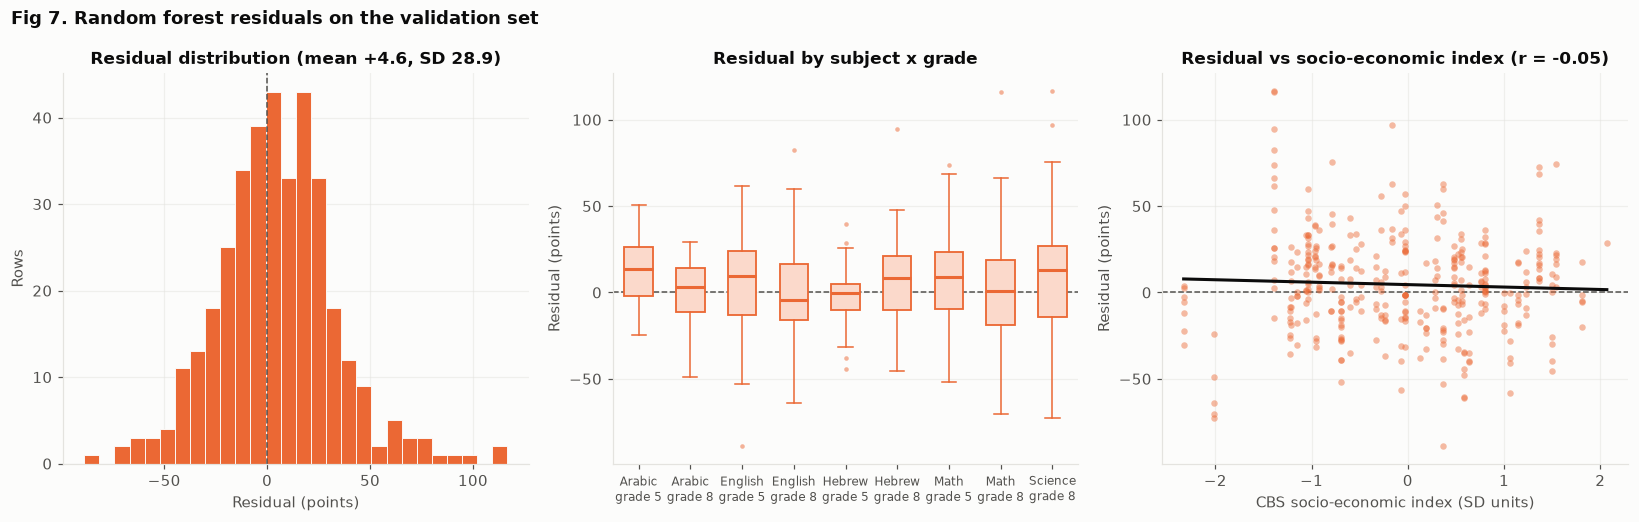

rows  mean    SD
subject_id shichva                  
Arabic     5          22  11.1  20.1
           8          22   1.0  18.1
English    5          40   4.2  30.8
           8          56   0.4  25.7
Hebrew     5          36  -1.8  17.3
           8          35   8.2  27.7
Math       5          40   8.3  26.6
           8          56   2.0  34.3
Science    8          55  10.0  37.9

In [129]:
chosen_name = "Random forest"
chosen_model = rf_search["unweighted"].best_estimator_
val_residual = pd.Series(y_val.to_numpy() - val_predictions[chosen_name], index=val_set.index)

# Same colour as the forest in Fig 6: these are its residuals
RESIDUAL_BOX = dict(BOX_STYLE)
RESIDUAL_BOX.update(
    boxprops=dict(facecolor="#fbd9cb", edgecolor=ORANGE, linewidth=1.2),
    medianprops=dict(color=ORANGE, linewidth=2),
    whiskerprops=dict(color=ORANGE), capprops=dict(color=ORANGE),
    flierprops=dict(marker="o", markersize=3, markerfacecolor=ORANGE, markeredgecolor="none", alpha=0.5),
)

fig, (ax_hist, ax_group, ax_ses) = plt.subplots(1, 3, figsize=(15, 4.8))

ax_hist.hist(val_residual, bins=28, color=ORANGE, edgecolor=SURFACE, linewidth=0.6)
ax_hist.axvline(0, color=INK_MUTED, linestyle="--", linewidth=1)
ax_hist.set(title=f"Residual distribution (mean {val_residual.mean():+.1f}, SD {val_residual.std():.1f})",
            xlabel="Residual (points)", ylabel="Rows")

val_groups = [key for key in GROUPS if ((val_set["subject_id"] == key[0]) & (val_set["shichva"] == key[1])).any()]
ax_group.axhline(0, color=INK_MUTED, linestyle="--", linewidth=1, zorder=1)
ax_group.boxplot([val_residual[(val_set["subject_id"] == s) & (val_set["shichva"] == g)] for s, g in val_groups],
                 tick_labels=[f"{SUBJECT_NAMES[s]}\ngrade {g}" for s, g in val_groups],
                 widths=0.55, zorder=2, **RESIDUAL_BOX)
ax_group.set(title="Residual by subject x grade", ylabel="Residual (points)")
ax_group.tick_params(axis="x", labelsize=8)
ax_group.grid(axis="x", visible=False)

ses = val_set["ses_index"]
ax_ses.axhline(0, color=INK_MUTED, linestyle="--", linewidth=1, zorder=1)
ax_ses.scatter(ses, val_residual, s=18, color=ORANGE, alpha=0.45, linewidths=0, zorder=2)
slope, intercept = np.polyfit(ses, val_residual, 1)
ses_grid = np.linspace(ses.min(), ses.max(), 50)
ax_ses.plot(ses_grid, intercept + slope * ses_grid, color=INK, linewidth=2, zorder=3)
ax_ses.set(title=f"Residual vs socio-economic index (r = {ses.corr(val_residual):.2f})",
           xlabel="CBS socio-economic index (SD units)", ylabel="Residual (points)")

fig.suptitle(f"Fig 7. {chosen_name} residuals on the validation set", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

display(val_residual.groupby([val_set["subject_id"].map(SUBJECT_NAMES), val_set["shichva"]])
        .agg(rows="count", mean="mean", SD="std").round(1))

**Fig 7.** Three checks on the forest's residuals.

- **Shape.** Symmetric and bell-shaped around zero, with no second hump, so there is no hidden group the model
  treats differently. The mean is +4.6 rather than 0 — the compression of Fig 6 showing up as a small bias. It
  is small next to the 28.9-point SD.
- **By subject × grade.** Every box straddles zero, so no test is systematically mispredicted. But the spreads
  differ a lot: an SD of 17 points in Hebrew grade 5 against 38 in Science grade 8. So the gaps have to be
  standardized within subject × grade before authorities are compared — a +30 residual in Hebrew grade 5 is a
  much rarer event than the same residual in Science grade 8.
- **Against the index.** Flat (r = −0.05). This is the important one. The model has already absorbed the
  socio-economic gradient, so what is left over is not explained by how rich or poor an authority is. The
  residuals therefore measure performance *relative to* socio-economic standing, which is exactly what the
  research question asks. Had this sloped, the gaps would still contain the gradient we want to hold constant.

### The test set, used once

Everything above was decided on the training and validation sets. The test set — 74 authorities, 547 rows, none
of them seen in training — is opened now for the model chosen on validation: the unweighted forest. The two
baselines are scored alongside it for reference. The weighted variants were rejected on validation and are not
re-run here; that is the point of holding the set back.

The forest is **not** refitted on train + validation first. That would score better, but then the model being
tested would not be the model that was selected.

In [130]:
test_results = []
for name, prediction in [
    ("Baseline: overall mean", predict_overall_mean(test_set)),
    ("Baseline: subject x grade mean", predict_group_mean(test_set)),
    (f"{chosen_name} (chosen on validation)", chosen_model.predict(X_test)),
]:
    test_results.append({
        "model": name,
        "R2": r2_score(y_test, prediction),
        "RMSE": mean_squared_error(y_test, prediction) ** 0.5,
        "MAE": mean_absolute_error(y_test, prediction),
        "R2 weighted": r2_score(y_test, prediction, sample_weight=w_test),
    })

test_prediction = chosen_model.predict(X_test)
test_residual = pd.Series(y_test.to_numpy() - test_prediction, index=test_set.index)

print(f"Test set: {len(test_set)} rows, {test_set['rashut'].nunique()} authorities, "
      f"{test_set['rashut'].isin(train_set['rashut']).sum()} of them seen in training")
print(f"Test residuals: mean {test_residual.mean():+.1f}, SD {test_residual.std():.1f}, "
      f"correlation with ses_index {test_set['ses_index'].corr(test_residual):.2f}")
pd.DataFrame(test_results).set_index("model").round(3)

Test set: 547 rows, 74 authorities, 0 of them seen in training
Test residuals: mean -3.3, SD 25.2, correlation with ses_index 0.07


,R2,RMSE,MAE,R2 weighted
model,,,,
Baseline: overall mean,-0.012,37.187,28.331,-0.007
Baseline: subject x grade mean,0.281,31.343,24.312,0.274
Random forest (chosen on validation),0.530,25.343,19.378,0.574


**Table 6. Test results.** On authorities it has never seen, the forest reaches **R² = 0.530, RMSE 25.3,
MAE 19.4**, against 0.281 for the subject × grade baseline. The residuals behave as they did on validation
(mean −3.3, SD 25.2, correlation with `ses_index` 0.07 — still flat).

The test score is slightly *better* than the validation score (0.530 vs 0.463). With only 48 validation and 74
test authorities, that is which authorities happened to land where, not a real improvement. The two agree:
**about half the variation in an authority's score is predictable** from its socio-economic characteristics
plus which test it is. The other half is not.

That other half is the rest of the project. An average miss of about 20 points, on tests spanning roughly
400–700, is the resolution at which we can call an authority an over- or under-performer.

One qualification: a row the model misses is an *average* it misses. Nothing here describes an individual
student, and the gaps must not be read that way.

## 4.2 Classification: high or low

## High or low: the same question as a classification

Here we turn the score into a two-way label and ask a classifier to tell the classes apart. The point is to
check the finding a second way, not to beat the regression.

**The rule:**

> A row is **High** if its `score` is above the median `score` of its own `(subject_id, shichva)` group, with
> that median computed on the **training set only**. Otherwise it is **Low**.

**Why within each subject and grade.** The training medians run from 518 in English grade 8 to 603 in Arabic
grade 5, against an overall median of 551. A single cut would label most Arabic grade 5 rows High and most
English grade 8 rows Low before socio-economic standing entered at all, and the classifier would just learn the
subject. The next cell shows this rather than asserting it.

**Why training only.** Otherwise a test row's label would depend on test scores. One consequence: validation
and test are then not exactly half High.

Everything else is reused from the regression, with **no sample weighting** — it was tested there and made
results worse. Expect 70 to 80% accuracy against a roughly 50% baseline.

In [131]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score)

group_median = train_set.groupby(GROUP_KEYS)[TARGET].median()
overall_median = train_set[TARGET].median()

def label_high(rows):
    own_median = rows.join(group_median.rename("cut"), on=GROUP_KEYS)["cut"]
    return (rows[TARGET] > own_median).astype(int)

y_train, y_val, y_test = label_high(train_set), label_high(val_set), label_high(test_set)
X_train, X_val, X_test = train_set[FEATURES], val_set[FEATURES], test_set[FEATURES]

balance = pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "share labelled High": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["train", "validation", "test"])
print(f"Overall training median: {overall_median:.1f}. Medians per subject x grade:")
display(group_median.rename(index=SUBJECT_NAMES, level=0).round(1).to_frame("training median"))
display(balance.round(3))


Overall training median: 551.0. Medians per subject x grade:


training median
subject_id shichva                 
Arabic     5                  603.0
           8                  564.0
English    5                  540.0
           8                  518.0
Hebrew     5                  543.5
           8                  559.0
Math       5                  564.0
           8                  539.0
Science    8                  579.5

,rows,share labelled High
train,840,0.492
validation,362,0.575
test,547,0.433


**The pooled median would have encoded the test, not the authority.** Under a single cut at 551, **87%** of
Arabic grade 5 rows are High and only **18%** of English grade 8 rows, with Science grade 8 at 75% and Hebrew
grade 5 at 28%. A classifier trained on that label would mostly be learning which exam a row came from.

Cut within each subject and grade, every group sits between 0.46 and 0.53.

The class balance also shows the training-only rule working: training is 49.2% High, validation 57.5%, test
43.3%. Those sets simply contain authorities sitting above or below the training medians. It does mean the
majority-class baseline scores differently on each set.

In [132]:
results = []

def record_classifier(name, y_true, prediction):
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_true, prediction),
        "precision": precision_score(y_true, prediction, zero_division=0),
        "recall": recall_score(y_true, prediction, zero_division=0),
        "F1": f1_score(y_true, prediction, zero_division=0),
    })

# Kept for the test table and as the reference point, but not listed as a model in Table 9
majority_class = int(y_train.mean() >= 0.5)
constant_accuracy = max(y_val.mean(), 1 - y_val.mean())

logistic = make_pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), drop_first=True)
logistic.fit(X_train, y_train)
record_classifier("Logistic regression", y_val, logistic.predict(X_val))

CLASSIFIER_GRID = {"model__max_depth": [None, 8, 16], "model__min_samples_leaf": [1, 3, 10],
                   "model__max_features": ["sqrt", 0.3, 1.0]}
forest_search = GridSearchCV(
    make_pipeline(RandomForestClassifier(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1),
                  drop_first=False),
    CLASSIFIER_GRID, cv=TUNING_CV, scoring="accuracy")
forest_search.fit(X_train, y_train, groups=train_groups)
forest_classifier = forest_search.best_estimator_
record_classifier("Random forest", y_val, forest_classifier.predict(X_val))

print("Forest tuning:", {k.removeprefix("model__"): v for k, v in forest_search.best_params_.items()},
      f"| CV accuracy {forest_search.best_score_:.3f} "
      f"(worst in grid {forest_search.cv_results_['mean_test_score'].min():.3f})")
print(f"\nTable 9. Validation results. For reference, the best any constant prediction could do on this "
      f"set is {constant_accuracy:.3f}, and a majority-class predictor gets "
      f"{accuracy_score(y_val, np.full(len(y_val), majority_class)):.3f}.")
display(pd.DataFrame(results).set_index("model").round(3))

Forest tuning: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1} | CV accuracy 0.726 (worst in grid 0.700)

Table 9. Validation results. For reference, the best any constant prediction could do on this set is 0.575, and a majority-class predictor gets 0.425.


,accuracy,precision,recall,F1
model,,,,
Logistic regression,0.702,0.727,0.769,0.748
Random forest,0.669,0.729,0.673,0.700


**Table 9. Logistic regression wins, the opposite of the regression track.**

Logistic reaches **70.2% accuracy and F1 0.748** on validation; the tuned forest gets 66.9% and 0.700 in F1. In
the regression the forest won by a wide margin, so the reversal is worth a sentence: binarizing throws away the
size of each score, and the forest's advantage came from fitting the extremes, which a High/Low cut discards.

Both models are about 20 points above the reference line printed above the table. Because the label splits each
subject and grade at its own median, the classes are near-balanced, so **no model that ignores the features can
do much better than about half**. A majority-class predictor actually scores 0.425 here, below a coin flip,
because the larger class in training is the smaller one in validation. We quote the reference rather than
listing it as a competing model, since "always say Low" is not a model anyone would use.

Test set, opened once for the model chosen on validation:


,accuracy,precision,recall,F1
model,,,,
Baseline: majority class,0.567,0.000,0.000,0.000
Logistic regression (chosen on validation),0.706,0.645,0.713,0.677


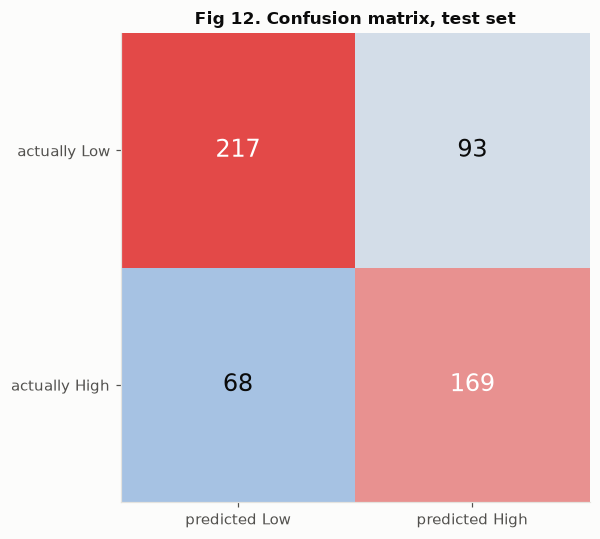

In [133]:
chosen_classifier_name = "Logistic regression"
chosen_classifier = logistic
test_prediction_class = chosen_classifier.predict(X_test)

test_rows = []
for name, prediction in [("Baseline: majority class", np.full(len(y_test), majority_class)),
                         (f"{chosen_classifier_name} (chosen on validation)", test_prediction_class)]:
    test_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, prediction),
        "precision": precision_score(y_test, prediction, zero_division=0),
        "recall": recall_score(y_test, prediction, zero_division=0),
        "F1": f1_score(y_test, prediction, zero_division=0),
    })
print("Test set, opened once for the model chosen on validation:")
display(pd.DataFrame(test_rows).set_index("model").round(3))

matrix = confusion_matrix(y_test, test_prediction_class)
fig, ax = plt.subplots(figsize=(5.6, 5))
ax.imshow(matrix, cmap=diverging.reversed(), vmin=0, vmax=matrix.max())
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["predicted Low", "predicted High"],
       yticklabels=["actually Low", "actually High"],
       title="Fig 12. Confusion matrix, test set")
ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, matrix[i, j], ha="center", va="center", fontsize=16,
                color="white" if matrix[i, j] > matrix.max() * 0.6 else INK)
fig.tight_layout()
plt.show()

**Fig 12 and the test set.** On authorities it has never seen, logistic gets **70.6% right**, with precision
0.645 and recall 0.713. The matrix: 217 Low and 169 High called correctly, against 93 Low called High and 68
High called Low.

The two error types are close in size, so the model is not biased towards one class. 70.6% against a roughly
50% reference is what we expected from a model with R² 0.530, so nothing is leaking.

In [134]:
# Does the classifier know anything the regression did not?
regression_prediction = chosen_model.predict(X_test)
regression_as_label = (regression_prediction
                       > test_set.join(group_median.rename("cut"), on=GROUP_KEYS)["cut"]).astype(int)

print("Turning the regression's predicted score into the same High/Low label:")
display(pd.DataFrame([
    {"source": "Logistic regression (classifier)",
     "accuracy": accuracy_score(y_test, test_prediction_class),
     "F1": f1_score(y_test, test_prediction_class, zero_division=0)},
    {"source": "Random forest regression, thresholded",
     "accuracy": accuracy_score(y_test, regression_as_label),
     "F1": f1_score(y_test, regression_as_label, zero_division=0)},
]).set_index("source").round(3))
print(f"The two agree on {100 * (test_prediction_class == regression_as_label.to_numpy()).mean():.1f}% "
      "of test rows.")

Turning the regression's predicted score into the same High/Low label:


,accuracy,F1
source,,
Logistic regression (classifier),0.706,0.677
"Random forest regression, thresholded",0.709,0.654


The two agree on 78.1% of test rows.


**The classification adds nothing the regression had not already given us.** Taking the random forest from
the regression, comparing its predicted score to the same group medians and reading off High or Low gives
**70.9% accuracy**, the same as the classifier's 70.6%. The two agree on 78% of test rows.

So the second angle confirms the first rather than extending it. Both say the same thing: about 70% of the time
you can tell from an authority's socio-economic profile and the test which side of its peers it will land on,
and about 30% of the time you cannot. That 30% is what the gap analysis turned into the over- and
under-performer list.

We report this rather than presenting the classifier as an independent success. The one thing it adds is a
readable statement of the limit: **about three authorities in ten are on the wrong side of where their
circumstances would put them.**

## 4.3 Over- and under-performing authorities

Added after the proposal feedback.

## Over- and under-performing authorities

This is the main question. An authority whose scores sit consistently above its prediction is doing
better than its socio-economic profile would suggest, and the point is to find those authorities and see what
they have in common.

Three things have to be right before any authority can be named.

**The gap has to be out-of-fold.** Up to now the forest was fitted on 121 training authorities and scored on
the 48 validation and 74 test ones. Its residuals for a training authority are smaller than they should be,
because it was fitted to that authority. Ranking all 243 together on those residuals would flatter the
training half. So we predict every row with `cross_val_predict` and `GroupKFold` on `rashut`: the table is
split into 5 folds of whole authorities, and each authority is predicted by a forest fitted on the other four
folds. No authority is ever predicted by a model that has seen it.

**The gaps have to be comparable.** A residual of 30 points is a much rarer event in Hebrew grade 5 than in
Science grade 8, because the spread differs by test (Fig 7). So each row's gap is standardized within its own
subject and grade: divided by the spread of the gaps in that test. A gap of +1 means "one standard deviation
better than predicted, for this test".

**One number per authority, plus a consistency check.** We average the standardized gaps of each authority's
rows and keep two things: the mean, and the share of that authority's rows pointing the same way as the mean.
An authority above its prediction in every single test is making a claim that one lucky result cannot.

In [135]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

X_all, y_all = data[FEATURES], data[TARGET]
oof_prediction = cross_val_predict(clone(chosen_model), X_all, y_all,
                                   cv=GroupKFold(n_splits=5), groups=data["rashut"])
oof_residual = pd.Series(y_all.to_numpy() - oof_prediction, index=data.index)

# Standardize within subject x grade, so a gap means the same thing in every test
by_test = oof_residual.groupby([data["subject_id"], data["shichva"]])
gap = (oof_residual - by_test.transform("mean")) / by_test.transform("std")

by_authority = gap.groupby(data["rashut"])
per_authority = pd.DataFrame({
    "rows": by_authority.size(),
    "gap": by_authority.mean(),
    "sd": by_authority.std(),
    "same_sign": by_authority.apply(lambda rows: float((np.sign(rows) == np.sign(rows.mean())).mean())),
    "ses_index": data.groupby("rashut")["ses_index"].first(),
    "ses_cluster": data.groupby("rashut")["ses_cluster"].first(),
}).join(authority_names[["name_en"]])

oof_r2 = r2_score(y_all, oof_prediction)
print(f"Out-of-fold R2 across all {data['rashut'].nunique()} authorities: {oof_r2:.3f} "
      f"(single split gave 0.463 on validation, 0.530 on test)")
print(f"Gap vs socio-economic index: r = {per_authority['gap'].corr(per_authority['ses_index']):.3f}")
print("\nSpread of the raw gaps, per test (points):")
display(oof_residual.groupby([data["subject_id"], data["shichva"]]).std().round(1)
        .rename(index=SUBJECT_NAMES, level=0).to_frame("SD"))

Out-of-fold R2 across all 243 authorities: 0.537 (single split gave 0.463 on validation, 0.530 on test)
Gap vs socio-economic index: r = 0.011

Spread of the raw gaps, per test (points):


SD
subject_id shichva      
Arabic     5        22.0
           8        24.4
English    5        28.0
           8        22.4
Hebrew     5        18.5
           8        21.1
Math       5        25.4
           8        30.2
Science    8        34.0

**The gaps are clean.** Out-of-fold R² is 0.537 over all 243 authorities, in line with the 0.463 and 0.530
from the single split, so nothing breaks when every authority is predicted out-of-fold.

The spread of the raw gaps runs from 18.5 points in Hebrew grade 5 to 34.0 in Science grade 8, which is why
they are standardized before averaging.

Most importantly, the gaps carry no socio-economic signal left: the correlation between an authority's mean gap
and its socio-economic index is **r = 0.011**. The model has already absorbed the gradient, so what remains
measures performance *relative to* socio-economic standing. That is exactly the quantity the research question
asks about.

In [136]:
# A single row cannot be checked for consistency, so those authorities are named and set aside
single_row = per_authority[per_authority["rows"] == 1]
eligible = per_authority[per_authority["rows"] >= 2]
print(f"Eligible: {len(eligible)} authorities. Set aside with one row only: {len(single_row)}")
display(single_row[["name_en", "gap", "ses_cluster"]].round(2))

# How many authorities would be flagged as we tighten the consistency requirement
rule_counts = pd.DataFrame({
    f"at least {int(share * 100)}% of rows agree": {
        "authorities": int((eligible["same_sign"] >= share).sum()),
        "of them above prediction": int(((eligible["same_sign"] >= share) & (eligible["gap"] > 0)).sum()),
    }
    for share in (0.5, 0.6, 0.75, 1.0)
}).T
display(rule_counts)

Eligible: 238 authorities. Set aside with one row only: 5


,name_en,gap,ses_cluster
rashut,,,
463,YAVNE'EL,0.74,3
1719,PARDESIYYA,-1.23,9
2675,KEFAR SHEMARYAHU,1.94,10
7400000,MEGILLOT DEAD SEA,-0.19,7
7500000,ARVOT HAYARDEN,-0.67,6


,authorities,of them above prediction
at least 50% of rows agree,214,108
at least 60% of rows agree,177,89
at least 75% of rows agree,122,61
at least 100% of rows agree,65,33


**Choosing the rule.** The table shows why the strictest option is the right one. Requiring only half an
authority's rows to agree flags 214 of 238, which is no filter at all: with gaps centred on zero, most
authorities will have a slim majority one way. At 75% it is still 122. Demanding that *every* row agree brings
it to 65, and that is the first point where the requirement actually means something.

So the rule is: **an authority is an over- or under-performer if every one of its rows falls on the same side
of its prediction.** That gives 65 authorities, 33 over and 32 under, out of 238 eligible. The remaining 173
are not "average" but simply not consistent enough to call either way, which is the honest answer for most of
them.

In [137]:
# The rule: every one of an authority's rows must fall on the same side of its prediction
is_flagged = eligible["same_sign"] >= 1.0
flagged = eligible[is_flagged].copy()
flagged["group"] = np.where(flagged["gap"] > 0, "over-performer", "under-performer")

print(f"Flagged: {len(flagged)} of {len(eligible)} eligible authorities "
      f"({(flagged['group'] == 'over-performer').sum()} over, "
      f"{(flagged['group'] == 'under-performer').sum()} under)")
print(f"Typical gap among the flagged: {flagged['gap'].abs().median():.2f} SD of its test, "
      f"which is about {flagged['gap'].abs().median() * oof_residual.std():.0f} score points")

SHOW = ["name_en", "rows", "gap", "sd", "ses_cluster"]
print("\nThe 10 clearest over-performers:")
display(flagged.nlargest(10, "gap")[SHOW].round(2))
print("The 10 clearest under-performers:")
display(flagged.nsmallest(10, "gap")[SHOW].round(2))

Flagged: 65 of 238 eligible authorities (33 over, 32 under)
Typical gap among the flagged: 0.97 SD of its test, which is about 26 score points

The 10 clearest over-performers:


,name_en,rows,gap,sd,ses_cluster
rashut,,,,,
5074,KAFAR YASIF,5,2.12,0.91,4
4500000,ALLONA,3,2.01,0.65,8
5371,FUREIDIS,5,1.84,0.80,3
4000000,EMEQ LOD,5,1.71,0.88,6
5116,ILUT,4,1.69,0.54,2
1222,RAMAT YISHAY,7,1.61,0.80,9
7800000,HAR HEVRON,7,1.43,0.90,5
6817,GIV'AT SHEMU'EL,7,1.40,0.54,8
5223,NAHEF,5,1.27,0.25,2


The 10 clearest under-performers:


,name_en,rows,gap,sd,ses_cluster
rashut,,,,,
5400000,HAARAVA HATIKHONA,7,-2.69,2.39,7
10603,LAQYE,5,-2.08,0.39,1
5413,JISR AZ-ZARQA,7,-1.88,0.46,2
9449,BASMAT TAB'UN,5,-1.83,1.02,3
80002,ZEFAT,7,-1.71,0.68,2
100000,HAGALIL HAELYON,7,-1.69,0.46,7
9985,BIR EL-MAKSUR,7,-1.42,1.00,2
3800000,ESHKOL,7,-1.37,0.88,6
85001,RAMLA,18,-1.23,0.74,4


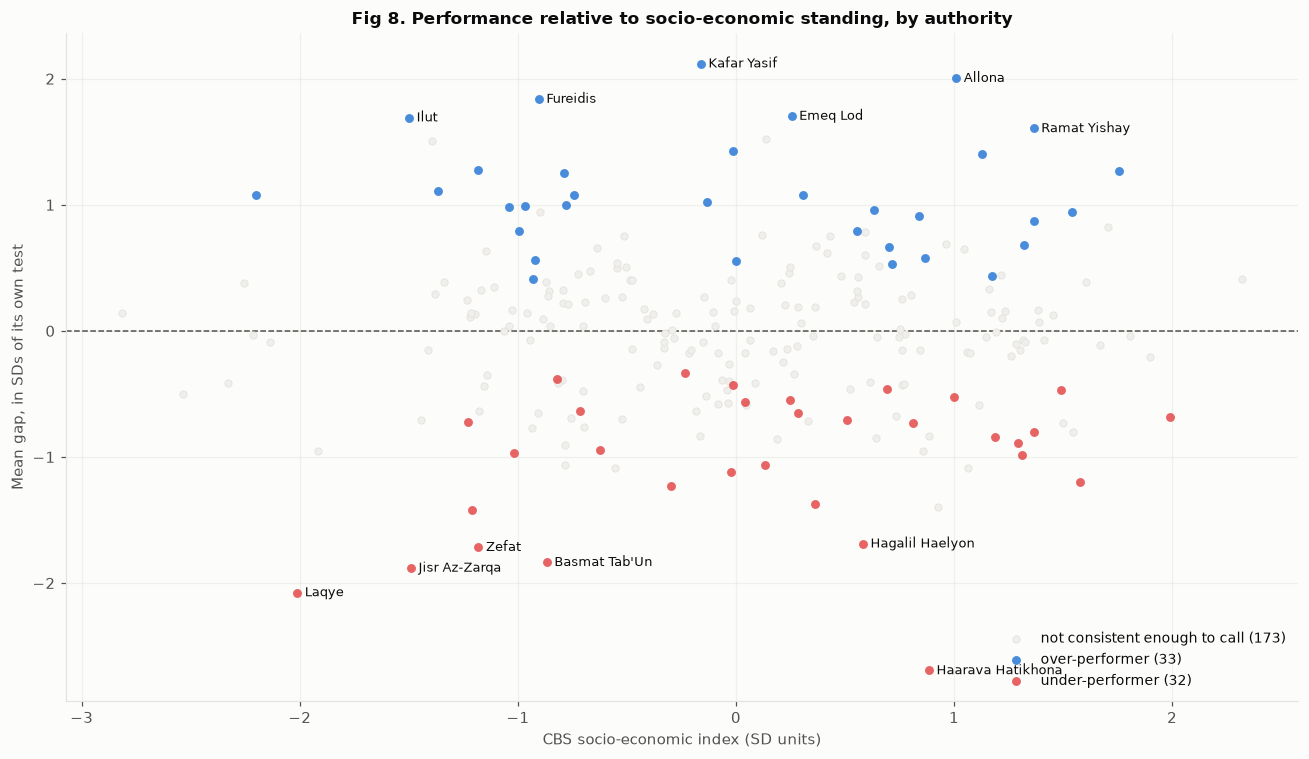

In [138]:
fig, ax = plt.subplots(figsize=(12, 7))

ax.axhline(0, color=INK_MUTED, linestyle="--", linewidth=1, zorder=1)
rest = eligible[~is_flagged]
ax.scatter(rest["ses_index"], rest["gap"], s=22, color=NEUTRAL, edgecolor=GRID,
           linewidths=0.6, zorder=2, label=f"not consistent enough to call ({len(rest)})")
for group, colour in [("over-performer", BLUE), ("under-performer", RED)]:
    part = flagged[flagged["group"] == group]
    ax.scatter(part["ses_index"], part["gap"], s=34, color=colour, alpha=0.85, linewidths=0,
               zorder=3, label=f"{group} ({len(part)})")

# Label the six clearest on each side
for _, r in pd.concat([flagged.nlargest(6, "gap"), flagged.nsmallest(6, "gap")]).iterrows():
    ax.annotate(r["name_en"].title(), (r["ses_index"], r["gap"]), xytext=(5, 0),
                textcoords="offset points", fontsize=8.5, va="center", color=INK)

ax.set(xlabel="CBS socio-economic index (SD units)",
       ylabel="Mean gap, in SDs of its own test",
       title="Fig 8. Performance relative to socio-economic standing, by authority")
ax.legend(frameon=False, loc="lower right", fontsize=9)
fig.tight_layout()
plt.show()

**Fig 8.** The vertical axis is what the project set out to measure: how far an authority sits from the score
its socio-economic profile predicts. The cloud is flat, with no tilt left to right, which is the visual version
of r = 0.011. Over- and under-performers appear at every socio-economic level, from Laqye and Jisr az-Zarqa in
clusters 1 and 2 to Haarava Hatikhona and Hagalil Haelyon in cluster 7.

That flatness is the result worth stating plainly. **Knowing an authority's socio-economic cluster tells you
nothing about whether it beats or misses its own prediction.** The gradient and the deviation from it are
separate phenomena.

The clearest over-performers are Kafar Yasif, Allona, Fureidis, Emeq Lod and Ilut. The clearest
under-performers are Haarava Hatikhona, Laqye, Jisr az-Zarqa, Basmat Tab'un and Zefat. Both lists mix sectors,
clusters and authority types.


### What distinguishes the two groups?

The plan was to compare over- and under-performers and report what separates them. There is a problem with
doing that on the CBS variables, and it is worth stating before the result.

The gaps come from a model that already used all 16 of those variables as predictors. Whatever they could
explain about an authority's score has already been removed from the gap. Looking for a difference in the same
variables is close to circular, and finding none would be the expected outcome rather than a finding.

So we look at two sets: the 16 variables the model used, and 6 authority-level variables it never saw, built
from the test-administration columns that were deliberately kept out of the features (number of schools, school
size, cohort size, students tested, response rate). Authority type (city, local council, regional council) was
also never a feature.

We measure the relationship as the **correlation between an authority's gap and each variable**, across all 238
eligible authorities. That is the same measure used in Fig 4 and Fig 5, and it suits the question better than
comparing the two flagged groups: it uses every authority rather than only the 65, and it keeps the size of
each gap instead of reducing it to a label. The medians of the two flagged groups are shown alongside, as
context.

In [139]:
rows_by_authority = data.copy()
rows_by_authority["students_per_school"] = (rows_by_authority["n_students_tested"]
                                           / rows_by_authority["n_schools_tested"])
rows_by_authority["cohort_size"] = (rows_by_authority["n_students_tested"]
                                    / (rows_by_authority["p_response"] / 100))
unseen = rows_by_authority.groupby("rashut").agg(
    schools_tested=("n_schools_tested", "mean"), schools=("n_schools", "mean"),
    students_per_school=("students_per_school", "mean"), students_tested=("n_students_tested", "mean"),
    cohort_size=("cohort_size", "mean"), response_rate=("p_response", "mean"))

seen = data.drop_duplicates("rashut").set_index("rashut")[["ses_index", "population"] + CBS_VARIABLES]
comparison = seen.join(unseen)
over_ids = flagged.index[flagged["group"] == "over-performer"]
under_ids = flagged.index[flagged["group"] == "under-performer"]

summary = []
for variable in comparison.columns:
    pair = pd.concat([eligible["gap"], comparison[variable]], axis=1).dropna()
    summary.append({
        "variable": variable,
        "used by the model": variable in FEATURES,
        "r with the gap": pair["gap"].corr(pair[variable]),
        "over-performers (median)": comparison.loc[over_ids, variable].median(),
        "under-performers (median)": comparison.loc[under_ids, variable].median(),
    })

characterization = pd.DataFrame(summary).set_index("variable")
characterization = characterization.reindex(
    characterization["r with the gap"].abs().sort_values(ascending=False).index)
print(f"Table 7. Each variable against the authority gap, over {len(eligible)} eligible authorities. "
      f"Medians are for the {len(over_ids)} over- and {len(under_ids)} under-performers.")
display(characterization.round(3))

# Authority type was never a model feature either
municipal_status = data.drop_duplicates("rashut").set_index("rashut")["municipal_status"]
authority_kind = pd.Series(np.where(municipal_status == 0, "city",
                           np.where(municipal_status == 99, "local council", "regional council")),
                           index=municipal_status.index, name="authority type")
print("Mean gap by authority type:")
display(eligible["gap"].groupby(authority_kind.loc[eligible.index]).agg(["count", "mean", "std"]).round(3))

Table 7. Each variable against the authority gap, over 238 eligible authorities. Medians are for the 33 over- and 32 under-performers.


,used by the model,r with the gap,over-performers (median),under-performers (median)
variable,,,,
response_rate,False,0.162,89.684,88.214
population,True,0.092,14845.313,16017.727
avg_vehicle_licence_fee,True,0.080,1365.040,1361.205
students_per_school,False,0.049,90.878,76.697
median_age,True,-0.033,27.000,30.000
pct_women_no_work_income_25_54,True,0.032,14.431,13.626
pct_income_support_20plus,True,-0.030,4.441,4.796
avg_years_schooling_25_54,True,0.028,12.717,12.711
pct_above_twice_avg_wage,True,0.026,9.862,9.475


Mean gap by authority type:


,count,mean,std
authority type,,,
city,75,0.043,0.610
local council,112,0.007,0.771
regional council,51,-0.087,0.821


**This is a null result, and it is the honest headline.** The analysis can say *which* authorities beat or miss
their socio-economic prediction, consistently and robustly. It cannot say *what* makes them do so. Everything
measured here about an authority, 16 socio-economic and demographic variables plus 6 structural ones and its
type, fails to separate Kafar Yasif from Jisr az-Zarqa once socio-economic standing is accounted for.

That points somewhere specific for interpretation. Whatever drives these gaps is plausibly school-level and
organisational, things like teaching quality, school leadership, municipal education policy or specific
programmes, and none of that appears in either dataset. The discussion returns to what it would take to test that.

In [140]:
# Does the list survive using the linear model's gaps instead of the forest's?
oof_linear = cross_val_predict(clone(linear_model), X_all, y_all,
                               cv=GroupKFold(n_splits=5), groups=data["rashut"])
linear_residual = pd.Series(y_all.to_numpy() - oof_linear, index=data.index)
by_test_linear = linear_residual.groupby([data["subject_id"], data["shichva"]])
linear_gap = ((linear_residual - by_test_linear.transform("mean"))
              / by_test_linear.transform("std")).groupby(data["rashut"]).mean()

agreement = pd.DataFrame({"forest": per_authority["gap"], "linear": linear_gap}).dropna()
print(f"Authority gaps, forest vs linear: r = {agreement['forest'].corr(agreement['linear']):.3f}")
print(f"Sign agreement on the {len(flagged)} flagged authorities: "
      f"{100 * (np.sign(linear_gap.loc[flagged.index]) == np.sign(flagged['gap'])).mean():.0f}%")

# Bonus check: the 28 authorities tested in more than one year
years_per_authority = data.groupby("rashut")["year"].nunique()
multi_year = years_per_authority[years_per_authority >= 2].index
by_year = gap.groupby([data["rashut"], data["year"]]).mean().loc[multi_year]
year_agreement = by_year.groupby(level=0).apply(
    lambda years: float((np.sign(years) == np.sign(years.mean())).mean()))
print(f"\nAuthorities tested in more than one year: {len(multi_year)}")
print(f"Of those, share whose years all agree in sign: {(year_agreement == 1).mean():.0%}")
print(f"Flagged authorities that are multi-year: {len(set(multi_year) & set(flagged.index))}")

Authority gaps, forest vs linear: r = 0.848
Sign agreement on the 65 flagged authorities: 98%

Authorities tested in more than one year: 28
Of those, share whose years all agree in sign: 82%
Flagged authorities that are multi-year: 5


**The list holds up.** Swapping the forest for the linear model, which is a different model family with a
different fit (out-of-fold R² 0.400 against 0.537), moves the authority gaps very little: the two correlate at
**r = 0.848**, and **98% of the 65 flagged authorities keep the same sign**. The over- and under-performers are a property of
the data, not of one model's quirks.

The year check points the same way. Of the 28 authorities tested in more than one year, 82% have every year
falling on the same side of their prediction, and 5 of the 65 flagged authorities are in that group. Year-to-
year consistency can only be checked for those 28, because the Meitzav rotates schools through three national
groups tested once every three years, so the other 215 authorities appear in a single year.

In [141]:
# Full ranked table for the appendix, and the figures the report refers back to
ranked = (per_authority.sort_values("gap", ascending=False)
          [["name_en", "rows", "gap", "sd", "same_sign", "ses_index", "ses_cluster"]]
          .round(3))
ranked.to_excel(Path("data") / "authority_gaps.xlsx")
print(f"Ranked gaps for all {len(ranked)} authorities written to data/authority_gaps.xlsx")
display(ranked.head(5))

Ranked gaps for all 243 authorities written to data/authority_gaps.xlsx


,name_en,rows,gap,sd,same_sign,ses_index,ses_cluster
rashut,,,,,,,
5074,KAFAR YASIF,5,2.121,0.914,1.0,-0.161,4
4500000,ALLONA,3,2.006,0.648,1.0,1.010,8
2675,KEFAR SHEMARYAHU,1,1.936,NaN,1.0,2.068,10
5371,FUREIDIS,5,1.840,0.803,1.0,-0.904,3
4000000,EMEQ LOD,5,1.705,0.885,1.0,0.255,6


# 5. Unsupervised Learning: Clustering

The proposal's fourth step: build groupings of authorities from the achievement data itself with K-Means, and
compare them against the official CBS socio-economic clusters.

## Grouping authorities by achievement

Can we build our own groups of authorities from the scores alone, and do they match the official
socio-economic clusters? This matters more after Table 7, since nothing we measured explained the gaps.

**Which subjects.** Not all nine subject and grade combinations. Only 10 of the 243 authorities have all nine,
and all 10 are mixed cities. Arabic is tested in Arabic-language authorities only and Hebrew in Hebrew-language
ones only, so including either would just make the groups rediscover the sector.

So we use the three grade 8 subjects taught in both sectors: English, Maths and Science. 223 of the 243
authorities have all three. Each column is standardized first, because the levels differ (517, 535, 574).

**Two inputs.** The scores, which group authorities by how well they do. And the authority gaps, which group them
by how far they sit from their prediction.

In [142]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

CORE = [(2, 8), (4, 8), (5, 8)]                      # English, Math, Science - grade 8, both sectors
CORE_LABELS = {(2, 8): "English gr 8", (4, 8): "Math gr 8", (5, 8): "Science gr 8"}

def build_profile(values, name):
    # Average over years first: 28 authorities are tested in more than one year
    wide = (pd.DataFrame({"rashut": data["rashut"], "subject_id": data["subject_id"],
                          "shichva": data["shichva"], name: values})
            .pivot_table(index="rashut", columns=["subject_id", "shichva"], values=name, aggfunc="mean"))
    return wide[CORE].rename(columns=CORE_LABELS).dropna()

score_profile = build_profile(data["score"].to_numpy(), "score")
gap_profile = build_profile(gap.to_numpy(), "gap")
official_cluster = data.groupby("rashut")["ses_cluster"].first()

print(f"Authorities with all three grade 8 subjects: {len(score_profile)} of {data['rashut'].nunique()}")
print("Mean score per column (why they are standardized first):")
display(score_profile.mean().round(1).to_frame("mean score"))

Authorities with all three grade 8 subjects: 223 of 243
Mean score per column (why they are standardized first):


,,mean score
subject_id,shichva,
2,8,516.8
4,8,535.1
5,8,573.9


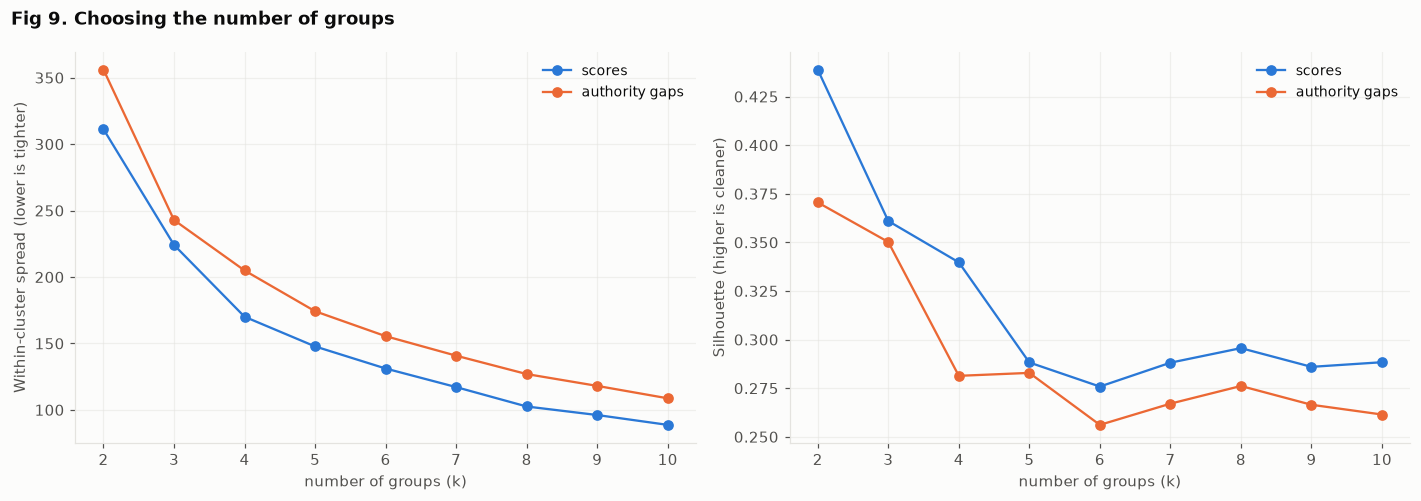

scores                gaps           
    inertia silhouette  inertia silhouette
k                                         
2   311.194      0.439  356.031      0.371
3   224.118      0.361  242.866      0.350
4   170.087      0.340  204.901      0.281
5   147.751      0.288  174.218      0.283
6   131.122      0.276  155.470      0.256
7   117.143      0.288  140.775      0.267
8   102.536      0.296  126.948      0.276
9    96.121      0.286  118.039      0.266
10   88.704      0.288  108.698      0.261

In [143]:
def sweep(frame):
    X = StandardScaler().fit_transform(frame)
    rows = []
    for k in range(2, 11):
        model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X)
        rows.append({"k": k, "inertia": model.inertia_, "silhouette": silhouette_score(X, model.labels_)})
    return X, pd.DataFrame(rows).set_index("k")

X_score, sweep_score = sweep(score_profile)
X_gap, sweep_gap = sweep(gap_profile)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, column, label in zip(axes, ["inertia", "silhouette"],
                             ["Within-cluster spread (lower is tighter)", "Silhouette (higher is cleaner)"]):
    ax.plot(sweep_score.index, sweep_score[column], marker="o", color=BLUE, label="scores")
    ax.plot(sweep_gap.index, sweep_gap[column], marker="o", color=ORANGE, label="authority gaps")
    ax.set(xlabel="number of groups (k)", ylabel=label, xticks=range(2, 11))
    ax.legend(frameon=False, fontsize=9)
fig.suptitle("Fig 9. Choosing the number of groups", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

display(pd.concat({"scores": sweep_score, "gaps": sweep_gap}, axis=1).round(3))

**Fig 9.** The spread falls smoothly with no clear elbow. Silhouette is highest at k = 2 for both inputs (0.44
for scores, 0.37 for gaps) and falls after that, so the data itself prefers two groups.

Two is too coarse for the comparison we want, so we report both: k = 2, which the measures prefer, and k = 10,
which lines up against the official 1 to 10 clusters.

In [144]:
def cluster_and_compare(frame, X, label):
    # How far apart are the two systems? For every authority, the distance between our group number
    # and its official cluster number. If the two were unrelated, shuffling our labels would give the
    # same average distance, so the shuffled figure is the reference point.
    results, assignments = [], {}
    shuffler = np.random.default_rng(RANDOM_STATE)
    for k in (2, 10):
        model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X)
        labels = pd.Series(model.labels_, index=frame.index)
        # Number our groups from weakest to strongest so the comparison reads in the same direction
        order = frame.mean(axis=1).groupby(labels).mean().sort_values().index
        ranked = labels.map({cluster: i + 1 for i, cluster in enumerate(order)})
        official = official_cluster.loc[frame.index]
        distance = (ranked - official).abs()
        if_unrelated = np.mean([np.abs(shuffler.permutation(ranked.to_numpy()) - official.to_numpy()).mean()
                                for _ in range(50)])
        results.append({
            "input": label, "k": k,
            "mean distance (clusters)": distance.mean(),
            "if unrelated": if_unrelated,
            "same number": int((distance == 0).sum()),
            "3 or more apart": int((distance >= 3).sum()),
        })
        assignments[k] = ranked
    return results, assignments

score_results, score_groups = cluster_and_compare(score_profile, X_score, "achievement scores")
gap_results, gap_groups = cluster_and_compare(gap_profile, X_gap, "authority gaps")

agreement = pd.DataFrame(score_results + gap_results).set_index(["input", "k"])
print(f"Table 8. How closely our groups line up with the official CBS clusters, over "
      f"{len(score_profile)} authorities.")
print("'Mean distance' is the average gap between the two cluster numbers for the same authority.")
print("'If unrelated' is the same figure after shuffling our labels, so it is the no-relationship mark.")
display(agreement.round(2))

print("Group centres, k = 10 on scores (original units, weakest group first):")
display(score_profile.groupby(score_groups[10]).mean().round(1))

Table 8. How closely our groups line up with the official CBS clusters, over 223 authorities.
'Mean distance' is the average gap between the two cluster numbers for the same authority.
'If unrelated' is the same figure after shuffling our labels, so it is the no-relationship mark.


mean distance (clusters)  if unrelated  same number  \
input              k                                                         
achievement scores 2                       3.57          3.61           15   
                   10                      1.54          2.70           55   
authority gaps     2                       3.70          3.71           12   
                   10                      2.59          2.78           32   

                       3 or more apart  
input              k                    
achievement scores 2               138  
                   10               43  
authority gaps     2               140  
                   10              104

Group centres, k = 10 on scores (original units, weakest group first):


subject_id,2,4,5
shichva,8,8,8
1,438.6,455.8,508.4
2,465.4,487.2,548.0
3,500.6,503.1,524.6
4,489.8,525.7,566.6
5,523.2,519.1,562.6
6,515.9,550.8,598.7
7,545.5,555.1,579.4
8,540.1,568.7,636.7
9,568.2,589.7,610.3


**Table 8. The two systems point the same way but disagree on the details.**

On the scores at k = 10, an authority sits on average **1.54 clusters** away from where our groups place it. If
the two systems were unrelated that distance would be **2.70**, so they clearly track each other. The group
centres rise steadily too, from 439/456/508 points in the weakest group to 562/616/677 in the strongest.

But only **55 of 223** authorities land on the same number, and **43** are three or more clusters apart. So the
two agree on direction while disagreeing about where the boundaries fall and who belongs where. The official
clusters predict the ranking reasonably well; they are not interchangeable with achievement.

On the gaps the distance is **2.59** against **2.78** if unrelated, with only 32 authorities matching. That is
as close to no relationship as this measure gets, and it is the expected check: the gaps were built to be
independent of socio-economic standing.

At k = 2 both inputs sit at the no-relationship mark (3.57 against 3.61, and 3.70 against 3.71), which is what
comparing two groups against ten should look like.

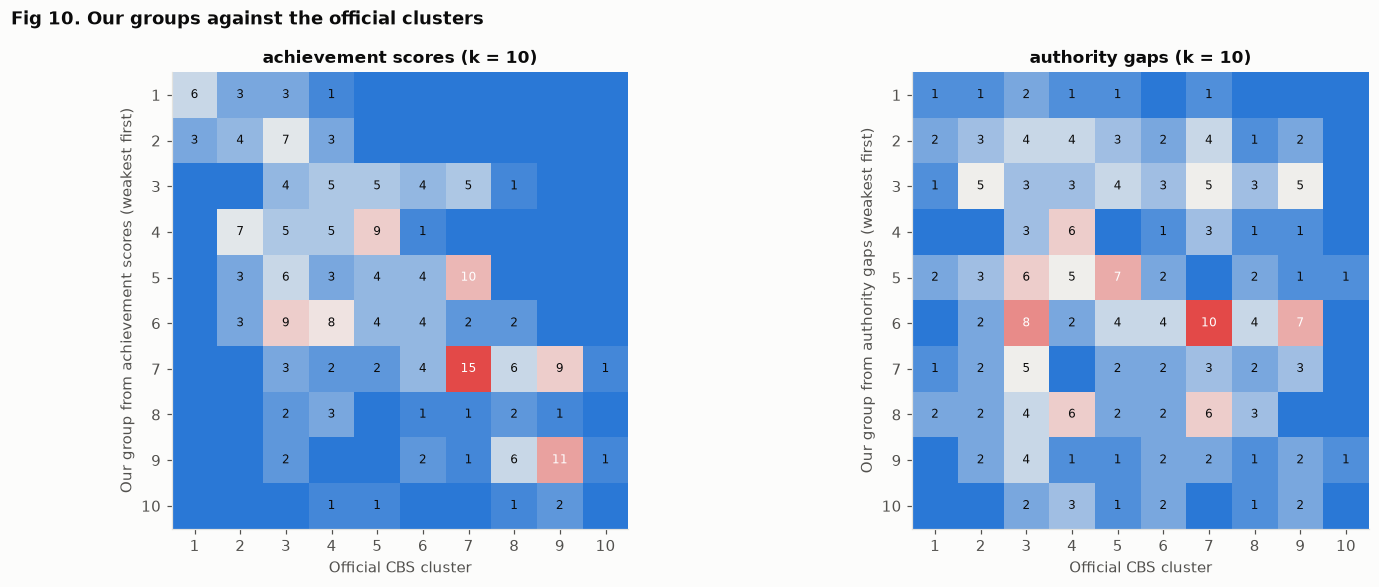

In [145]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))

for ax, (name, groups) in zip(axes, [("achievement scores", score_groups), ("authority gaps", gap_groups)]):
    table = pd.crosstab(groups[10], official_cluster.loc[groups[10].index])
    table = table.reindex(index=range(1, 11), columns=range(1, 11), fill_value=0)
    image = ax.imshow(table, cmap=diverging.reversed(), vmin=0, vmax=table.values.max())
    ax.set(xticks=range(10), yticks=range(10),
           xticklabels=range(1, 11), yticklabels=range(1, 11),
           xlabel="Official CBS cluster", ylabel=f"Our group from {name} (weakest first)",
           title=f"{name} (k = 10)")
    ax.grid(False)
    for i in range(10):
        for j in range(10):
            count = table.iat[i, j]
            if count:
                ax.text(j, i, count, ha="center", va="center", fontsize=8,
                        color="white" if count > table.values.max() * 0.6 else INK)

fig.suptitle("Fig 10. Our groups against the official clusters", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Fig 10.** The left panel shows a loose diagonal: low official clusters tend to land in low achievement
groups, but the band is wide. The right panel, from the gaps, has no diagonal at all. The counts are spread
evenly, which is what independence looks like.

In [146]:
# Where do the two systems disagree, and are those the authorities the gap analysis flagged?
achievement_rank = score_groups[10]
difference = (achievement_rank - official_cluster.loc[achievement_rank.index]).rename("difference")
flagged_label = flagged["group"].map({"over-performer": "over", "under-performer": "under"})

mismatch = pd.DataFrame({
    "our group": achievement_rank,
    "official cluster": official_cluster.loc[achievement_rank.index],
    "difference": difference,
}).join(authority_names[["name_en"]])
mismatch["gap analysis"] = [flagged_label.get(a, "") for a in mismatch.index]

print(f"Authorities at least 3 clusters away from their achievement group: "
      f"{int(difference.abs().ge(3).sum())} of {len(difference)}. "
      f"Mean distance: {difference.abs().mean():.2f} clusters.")
SHOW = ["name_en", "our group", "official cluster", "difference", "gap analysis"]
print("\nDoing better than their official cluster suggests:")
display(mismatch.nlargest(8, "difference")[SHOW])
print("Doing worse:")
display(mismatch.nsmallest(8, "difference")[SHOW])

overlap = pd.crosstab(achievement_rank.loc[flagged_label.index.intersection(achievement_rank.index)],
                      flagged_label).reindex(range(1, 11), fill_value=0)
overlap["share over"] = (overlap["over"] / overlap.sum(axis=1)).round(2)
print("The flagged authorities across our achievement groups:")
display(overlap)

Authorities at least 3 clusters away from their achievement group: 43 of 223. Mean distance: 1.54 clusters.

Doing better than their official cluster suggests:


,name_en,our group,official cluster,difference,gap analysis
rashut,,,,,
5074,KAFAR YASIF,10,4,6,over
6338,KAFAR BARA,9,3,6,
42010,MAJDAL SHAMS,9,3,6,
4929,DEIR HANNA,8,3,5,over
5025,YIRKA,8,3,5,over
7800000,HAR HEVRON,10,5,5,over
5058,KAOKAB ABU AL-HIJA,8,4,4,
5173,MAZRA'A,8,4,4,


Doing worse:


,name_en,our group,official cluster,difference,gap analysis
rashut,,,,,
3500000,YO'AV,3,8,-5,
100000,HAGALIL HAELYON,3,7,-4,under
2600000,MATTE YEHUDA,3,7,-4,
3300000,BE'ER TUVEYA,3,7,-4,
3600000,HOF ASHQELON,3,7,-4,
3700000,SHA'AR HANEGEV,3,7,-4,
6668,OMER,7,10,-3,
10348,QIRYAT MAL'AKHI,1,4,-3,


The flagged authorities across our achievement groups:


group,over,under,share over
row_0,,,
1,0,4,0.00
2,1,5,0.17
3,0,5,0.00
4,0,2,0.00
5,0,6,0.00
6,8,0,1.00
7,4,6,0.40
8,4,0,1.00
9,5,0,1.00


**The two methods point at the same authorities.** Four of the eight authorities doing best relative to their
official cluster are over-performers from the gap analysis: Kafar Yasif (+6 clusters), Deir Hanna (+5), Yirka (+5) and Har
Hevron (+5). Hagalil Haelyon (-4) is an under-performer from the gap analysis.

**The under-performing end has a pattern Table 7 missed.** Six of the eight authorities furthest below their
official cluster are regional councils. Table 7 found authority type almost unrelated to the gap on average
(+0.04, +0.01, -0.09), and both are true: regional councils are not worse on average, but they are
over-represented at the extreme. A regional council averages several small separate communities, so one number
hides more variation than a town's does.

⚠️ This is not independent confirmation. The gaps correlate 0.75 with raw mean score, and the groups are built
from those same scores, so some agreement is built in. What it shows is that the finding survives a second
method.

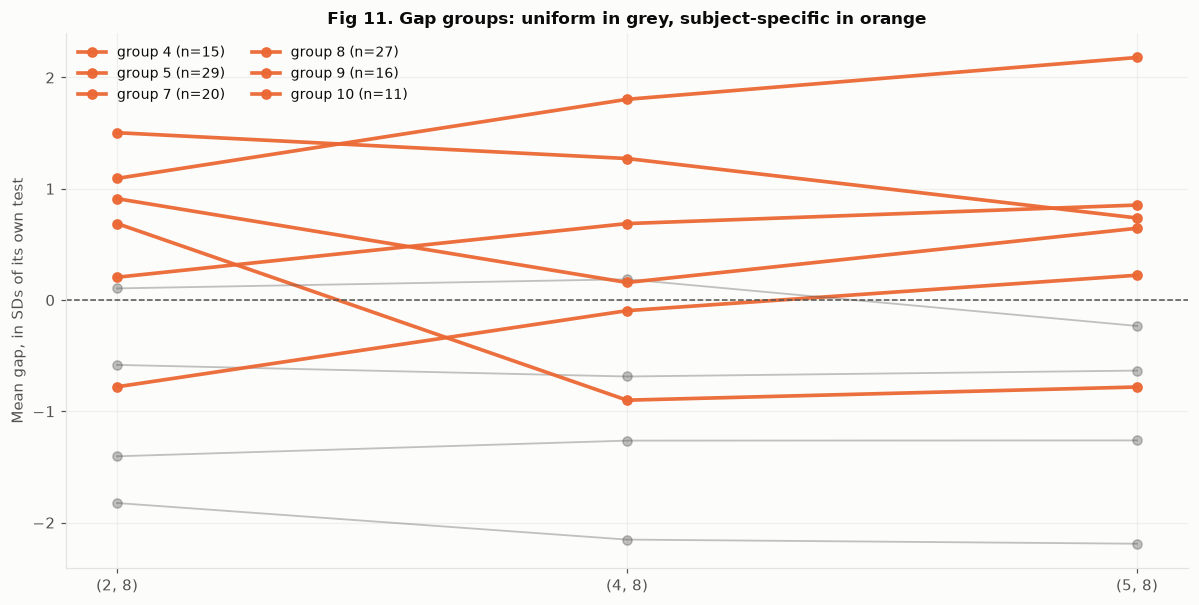

,level (mean of the three),spread across subjects,authorities
1,-2.06,0.37,7
2,-1.31,0.14,25
3,-0.63,0.10,32
4,-0.33,1.59,15
5,-0.22,1.00,29
6,0.02,0.42,41
7,0.57,0.75,20
8,0.58,0.65,27
9,1.17,0.77,16
10,1.69,1.09,11


In [147]:
# Do the gap groups differ in shape, or only in level?
gap_centres = gap_profile.groupby(gap_groups[10]).mean()
shape = pd.DataFrame({
    "level (mean of the three)": gap_centres.mean(axis=1),
    "spread across subjects": gap_centres.max(axis=1) - gap_centres.min(axis=1),
    "authorities": gap_groups[10].value_counts().sort_index(),
})

fig, ax = plt.subplots(figsize=(11, 5.6))
positions = np.arange(len(gap_centres.columns))
for group, centre in gap_centres.iterrows():
    uniform = shape.loc[group, "spread across subjects"] < 0.5
    ax.plot(positions, centre.to_numpy(), marker="o", linewidth=2.4 if not uniform else 1.2,
            alpha=0.95 if not uniform else 0.35,
            color=ORANGE if not uniform else INK_MUTED,
            label=f"group {group} (n={shape.loc[group, 'authorities']})" if not uniform else None)
ax.axhline(0, color=INK_MUTED, linestyle="--", linewidth=1)
ax.set(xticks=positions, xticklabels=[c for c in gap_centres.columns],
       ylabel="Mean gap, in SDs of its own test",
       title="Fig 11. Gap groups: uniform in grey, subject-specific in orange")
ax.legend(frameon=False, fontsize=9, ncol=2)
fig.tight_layout()
plt.show()

display(shape.round(2))

**Fig 11. Some authorities are subject-specific.** This is the one thing the gap analysis above could not
show, because it reduced each authority to a single number.

At k = 2 the two gap groups differ only in level: their spread across the three subjects is 0.05 and 0.06, so
each sits flat, above or below prediction by about the same amount everywhere. At that resolution the
clustering adds nothing.

At k = 10 four groups are tilted. Group 4 (15 authorities) is above prediction in English and below it in Maths
and Science, a spread of 1.59 SDs. Group 5 (29 authorities) is the reverse.

So over-performing is not one thing. Some authorities beat their prediction everywhere, others in one subject
while falling behind in another. That matters for a policy reader: an authority strong in English and weak in
Maths needs something different from one that is uniformly behind.

In [148]:
# Save the group assignments alongside the gaps for the appendix
clusters_out = pd.DataFrame({
    "achievement group (k=10)": score_groups[10],
    "achievement group (k=2)": score_groups[2],
    "gap group (k=10)": gap_groups[10],
    "official cluster": official_cluster.loc[score_profile.index],
}).join(authority_names[["name_en"]]).join(per_authority[["gap", "rows"]])
clusters_out.to_excel(Path("data") / "authority_clusters.xlsx")
print(f"Group assignments for {len(clusters_out)} authorities written to data/authority_clusters.xlsx")
display(clusters_out.head(5))

Group assignments for 223 authorities written to data/authority_clusters.xlsx


,achievement group (k=10),achievement group (k=2),gap group (k=10),official cluster,name_en,gap,rows
rashut,,,,,,,
281,7,2,3,9,MAZKERET BATYA,-0.202848,7
315,2,1,3,3,OFAQIM,-0.476577,5
703,6,2,8,4,ASHDOD,1.021366,19
992,3,1,4,3,MIZPE RAMON,0.231411,7
1222,10,2,10,9,RAMAT YISHAY,1.607238,7


# 6. Feature Importance

The proposal's sixth step: extract importance from the Random Forest to see whether the socio-economic index
outweighs grade level and subject.

## Which variables actually matter

The proposal asked whether the socio-economic index outweighs grade and subject. Two things make a naive
ranking misleading here.

**The categoricals arrive split.** `subject_id`, `shichva`, `norm_id` and `year` become 13 dummy columns
against 16 numeric features. Reporting importance per column would make every categorical look weak just from
being encoded, so we add them back up per variable.

**The socio-economic variables are near-duplicates.** `ses_index` correlates above 0.8 with eight CBS variables
(Fig 5). Permutation importance shuffles one variable and measures the damage, so when eight carry the same
information, shuffling any one does almost nothing. That is the correlation, not evidence of unimportance.

So we report three per-variable views, then the comparison collinearity cannot distort: shuffling the whole
socio-economic block against the whole test-identity block.

Expect test identity to win: the subject × grade baseline alone reached R² 0.297 of the full model's 0.537.

In [149]:
from sklearn.inspection import permutation_importance

# The classification section reassigned y_val to the High/Low label, so the regression target is re-derived here
score_val = val_set[TARGET]
X_val_features = val_set[FEATURES]

encoded_columns = chosen_model[:-1].get_feature_names_out()

# Which original variable each column belongs to. Subject and sector arrive already encoded, so their
# columns are named subject_* and sector_*; shichva and year are encoded inside the pipeline.
def original_variable(column):
    bare = column.split("__", 1)[1]
    if bare in NUMERIC_FEATURES:
        return bare
    if bare in SUBJECT_DUMMIES:
        return "subject_id"
    if bare in SECTOR_DUMMIES:
        return "norm_id"
    for variable in CATEGORICAL_FEATURES:
        if bare.startswith(variable + "_"):
            return variable
    return bare

owner = pd.Series([original_variable(c) for c in encoded_columns], index=encoded_columns)
VARIABLES = NUMERIC_FEATURES + CATEGORICAL_FEATURES + ["subject_id", "norm_id"]
print(f"{len(encoded_columns)} encoded columns from {len(VARIABLES)} variables. Columns per variable:")
print(owner.value_counts().loc[["subject_id", "norm_id"] + CATEGORICAL_FEATURES].to_string())

# 1. the forest's built-in (impurity) importance
impurity = (pd.Series(chosen_model.named_steps["model"].feature_importances_, index=encoded_columns)
            .groupby(owner).sum())

# 2. permutation importance, on validation, measured as lost R2.
# For variables held in a single column this is sklearn's permutation_importance. Subject and sector
# live across several indicator columns, and shuffling one of them leaves the others carrying the same
# information, so those are shuffled as a group instead - otherwise they would look falsely unimportant.
SINGLE_COLUMN = NUMERIC_FEATURES + CATEGORICAL_FEATURES
single = permutation_importance(chosen_model, X_val_features[FEATURES], score_val,
                                n_repeats=15, random_state=RANDOM_STATE, scoring="r2")
permutation = pd.Series(single.importances_mean, index=FEATURES)[SINGLE_COLUMN]

reference_r2 = r2_score(score_val, chosen_model.predict(X_val_features))
shuffler = np.random.default_rng(RANDOM_STATE)

def joint_permutation(columns, repeats=15):
    # Shuffle a block of columns together, keeping rows aligned within the block
    drops = []
    for _ in range(repeats):
        shuffled = X_val_features.copy()
        shuffled[columns] = shuffled[columns].to_numpy()[shuffler.permutation(len(shuffled))]
        drops.append(reference_r2 - r2_score(score_val, chosen_model.predict(shuffled)))
    return float(np.mean(drops))

permutation["subject_id"] = joint_permutation(SUBJECT_DUMMIES)
permutation["norm_id"] = joint_permutation(SECTOR_DUMMIES)

# 3. the logistic classifier's standardized coefficients, absolute, summed per variable
logistic_columns = logistic[:-1].get_feature_names_out()
logistic_owner = pd.Series([original_variable(c) for c in logistic_columns], index=logistic_columns)
coefficients = (pd.Series(np.abs(logistic.named_steps["model"].coef_[0]), index=logistic_columns)
                .groupby(logistic_owner).sum())

importance = pd.DataFrame({
    "impurity (forest)": impurity,
    "permutation (forest)": permutation,
    "|coefficient| (logistic)": coefficients,
}).fillna(0).sort_values("permutation (forest)", ascending=False)
display(importance.round(4))

29 encoded columns from 20 variables. Columns per variable:
subject_id    5
norm_id       3
shichva       2
year          3


,impurity (forest),permutation (forest),|coefficient| (logistic)
subject_id,0.2719,0.5048,1.9044
shichva,0.1071,0.1694,0.0076
income_per_capita,0.0436,0.0209,0.5594
pct_income_support_20plus,0.0321,0.0183,0.3184
year,0.0326,0.0173,1.1285
population,0.0275,0.0124,0.3216
avg_days_abroad,0.0382,0.0124,0.1739
norm_id,0.0102,0.0117,3.9443
ses_index,0.0450,0.0112,0.0302
avg_years_schooling_25_54,0.0444,0.0112,0.7799


**Subject and grade dominate, and it is not close.** By permutation importance, shuffling `subject_id` costs
**0.505 of R²** and `shichva` **0.169**. The next variable down is `income_per_capita` at 0.021. `ses_index`
itself ranks **ninth, at 0.011**.

The three views agree on the top two and disagree below that, which is what the method differences predict.

- **Impurity** spreads credit across the correlated CBS variables, giving `vehicles_per_100_17plus` 0.075, more
  than `ses_index` at 0.045.
- **Permutation** does the opposite, giving each correlated variable almost nothing.
- **The logistic coefficients** rank `norm_id` first (3.94) while permutation puts it eighth. Sector is a strong
  linear signal, but the forest can rebuild it from the other variables.

One oddity worth reporting: `pct_academic_degree_27_54` has permutation importance of **-0.012**, so
predictions get slightly better when it is shuffled. On this split it is noise.

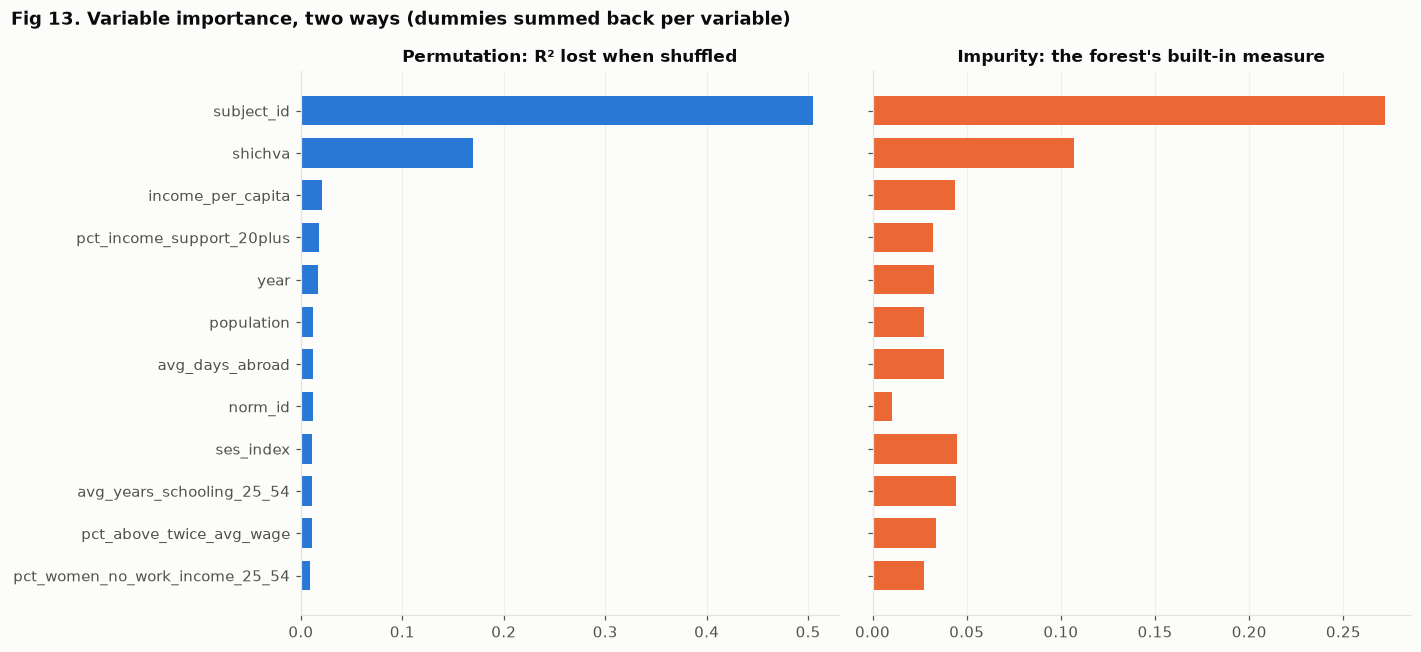

In [150]:
TOP = 12
top_variables = importance.head(TOP).index[::-1]
positions = np.arange(len(top_variables))

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
for ax, (column, colour, title) in zip(axes, [
        ("permutation (forest)", BLUE, "Permutation: R² lost when shuffled"),
        ("impurity (forest)", ORANGE, "Impurity: the forest's built-in measure")]):
    values = importance.loc[top_variables, column]
    ax.barh(positions, values, color=colour, height=0.7)
    ax.axvline(0, color=INK_MUTED, linewidth=1)
    ax.set(yticks=positions, yticklabels=top_variables, title=title)
    ax.grid(axis="y", visible=False)

fig.suptitle("Fig 13. Variable importance, two ways (dummies summed back per variable)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Fig 13.** The left panel ranks the variables that cannot be replaced; the right shows how impurity spreads
credit among substitutes. Together they say: the test a row comes from is irreplaceable, and no single
socio-economic variable is, because they all stand in for each other. Neither panel answers the proposal's
question on its own.

In [151]:
SOCIO_BLOCK = NUMERIC_FEATURES                              # ses_index, population, the 14 CBS variables
TEST_BLOCK = CATEGORICAL_FEATURES + DUMMY_FEATURES          # grade, year, subject and sector columns

baseline_r2 = r2_score(score_val, chosen_model.predict(X_val_features))
generator = np.random.default_rng(RANDOM_STATE)

def block_importance(columns, repeats=20):
    # Shuffle a whole block of columns together, keeping rows aligned within the block, so that
    # correlated variables lose their information at the same time
    drops = []
    for _ in range(repeats):
        shuffled = X_val_features.copy()
        shuffled[columns] = shuffled[columns].to_numpy()[generator.permutation(len(shuffled))]
        drops.append(baseline_r2 - r2_score(score_val, chosen_model.predict(shuffled)))
    return {"R2 lost": np.mean(drops), "sd over repeats": np.std(drops), "variables": len(columns)}

blocks = pd.DataFrame({
    f"socio-economic block": block_importance(SOCIO_BLOCK),
    f"test identity block": block_importance(TEST_BLOCK),
    "subject and grade only": block_importance(SUBJECT_DUMMIES + ["shichva"]),
    "ses_index alone": block_importance(["ses_index"]),
}).T[["variables", "R2 lost", "sd over repeats"]]

print(f"Table 10. Block permutation on validation. Baseline R2 = {baseline_r2:.3f}.")
print("A loss larger than the baseline means the model ends up worse than predicting the mean.")
display(blocks.round(3))

Table 10. Block permutation on validation. Baseline R2 = 0.463.
A loss larger than the baseline means the model ends up worse than predicting the mean.


,variables,R2 lost,sd over repeats
socio-economic block,16.0,0.374,0.034
test identity block,10.0,0.609,0.059
subject and grade only,6.0,0.602,0.051
ses_index alone,1.0,0.012,0.005


**Table 10. The answer to the proposal's question is no.** Shuffling the four test-identity variables costs
**0.609 of R²**; shuffling all sixteen socio-economic variables costs **0.374**. Subject and grade alone cost
0.602. So which test a row is carries more of this model's predictive power than everything we know about the
authority combined.

The losses exceed the 0.463 baseline because a model with shuffled test identity predicts worse than guessing
the mean, so R² goes negative.

**The contrast between the two measures is the point of this step.** Per-variable permutation says `ses_index`
is worth 0.011. The block permutation says socio-economic information is worth 0.374. Both are correct:
`ses_index` alone costs 0.012 when shuffled because the other fifteen variables rebuild it. Reporting only the
first would have been misleading.

So: **socio-economic standing does not outweigh grade and subject, but it is not negligible either.** It is the
second of two large blocks, spread so thinly across correlated variables that none looks important alone.

# 7. Robustness and Limitations

Not in the proposal. The sensitivity analysis answers the feedback's request for cross-validation and honest
reporting, and the closing section states the limitation the feedback asked us to name.

## Does any of this depend on the choices we made?

Six judgement calls shaped the analysis: which years, combined totals or sector rows, whether to drop small
cells, which socio-economic measure, how to split, and which model family. Here we rebuild the whole pipeline
under each alternative.

**The metric is the authority list, not R².** A variation could leave R² untouched while reshuffling who gets
flagged. Since the 65 flagged authorities are the output, what matters is how many survive and whether any
change direction.

Three were already answered earlier and are collected here rather than re-run: the row-level split, the
weighting, and forest versus linear for the gaps.

⚠️ Each variant reuses the baseline's tuned hyperparameters rather than re-tuning. That keeps the comparison
about the data choice and the runtime short, but mildly disadvantages a variant that wanted different
settings.

In [152]:
from sklearn.linear_model import LinearRegression as _LinearRegression

raw_education = pd.read_csv(EDUCATION_PATH)          # before the year filter and the norm_id fix
BEST_FOREST = {k.removeprefix("model__"): v for k, v in rf_search["unweighted"].best_params_.items()}
print("Reusing the baseline forest settings:", BEST_FOREST)

def rebuild(years=(2016, 2017, 2018), grain="totals", min_tested=0, ses="ses_index"):
    rows = raw_education[raw_education["year"].isin(years)].reset_index(drop=True)
    if grain == "totals":
        has_total = rows["norm_id"].eq(1).groupby([rows[k] for k in KEYS]).transform("any")
        rows = rows[~has_total | rows["norm_id"].eq(1)]
    else:
        rows = rows[rows["norm_id"] != 1]
    rows = rows.reset_index(drop=True)
    rows["cbs_key"] = rows["rashut"].map(cbs_key_from_rashut)
    merged = rows.merge(cbs, on="cbs_key", how="left")
    merged = merged[merged["ses_index"].notna() & merged["score"].notna()]
    if min_tested:
        merged = merged[merged["n_students_tested"] >= min_tested]
    merged = merged.drop(columns=[c for c in merged.columns if c.endswith(("_z", "_rank"))])
    merged = merged.reset_index(drop=True)
    merged["subject_id"] = merged["subject_id"].map(SUBJECT_CODES).astype(int)
    # Encode subject and sector the same way the cleaning step did, so every variant matches the baseline
    for code, label in SUBJECT_LABELS.items():
        merged[f"subject_{label}"] = (merged["subject_id"] == code).astype(int)
    for code, label in SECTOR_LABELS.items():
        merged[f"sector_{label}"] = (merged["norm_id"] == code).astype(int)
    return (merged,
            [ses, "population"] + CBS_VARIABLES,
            ["shichva", "year"] + SUBJECT_DUMMIES + SECTOR_DUMMIES)

def variant_pipeline(numeric, categorical, model):
    numeric_steps = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    already_encoded = [c for c in categorical if c not in ("shichva", "year")]
    prep = ColumnTransformer([("num", numeric_steps, numeric),
                              ("grade", OneHotEncoder(handle_unknown="ignore"), ["shichva"]),
                              ("already_encoded", "passthrough", already_encoded),
                              ("year", OneHotEncoder(handle_unknown="ignore"), ["year"])])
    return Pipeline([("prep", prep), ("model", model)])

def flag_under(frame, numeric, categorical, model=None):
    # The whole gap chain: out-of-fold prediction, standardize within test, flag the consistent ones
    model = model or RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE,
                                           n_jobs=-1, **BEST_FOREST)
    X, y = frame[numeric + categorical], frame["score"]
    out_of_fold = cross_val_predict(variant_pipeline(numeric, categorical, model), X, y,
                                    cv=GroupKFold(n_splits=5), groups=frame["rashut"])
    residual = pd.Series(y.to_numpy() - out_of_fold, index=frame.index)
    by_test = residual.groupby([frame["subject_id"], frame["shichva"]])
    variant_gap = (residual - by_test.transform("mean")) / by_test.transform("std")
    by_authority = variant_gap.groupby(frame["rashut"])
    per = pd.DataFrame({"rows": by_authority.size(), "gap": by_authority.mean(),
                        "same_sign": by_authority.apply(
                            lambda s: float((np.sign(s) == np.sign(s.mean())).mean()))})
    candidates = per[per["rows"] >= 2]
    picked = candidates[candidates["same_sign"] >= 1.0]
    return {"rows": len(frame), "authorities": frame["rashut"].nunique(),
            "r2": r2_score(y, out_of_fold), "flagged": set(picked.index),
            "over": set(picked.index[picked["gap"] > 0]), "under": set(picked.index[picked["gap"] < 0])}

# The baseline must reproduce what the notebook already reported, or the rebuild is wrong
baseline_frame, baseline_numeric, baseline_categorical = rebuild()
runs = {"baseline (as reported above)": flag_under(baseline_frame, baseline_numeric, baseline_categorical)}
check = runs["baseline (as reported above)"]
print(f"Rebuilt baseline: {check['rows']} rows, {check['authorities']} authorities, "
      f"out-of-fold R2 {check['r2']:.3f}, {len(check['flagged'])} flagged "
      f"({len(check['over'])} over / {len(check['under'])} under)")
assert (check["rows"], check["authorities"], len(check["flagged"])) == (len(data), data["rashut"].nunique(), len(flagged)), \
    "the rebuild does not reproduce the baseline, so the variants below cannot be trusted"
print("Matches the figures reported earlier, so the variants are comparable.")

Reusing the baseline forest settings: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}
Rebuilt baseline: 1749 rows, 243 authorities, out-of-fold R2 0.537, 65 flagged (33 over / 32 under)
Matches the figures reported earlier, so the variants are comparable.


In [153]:
VARIATIONS = [
    ("Sector rows instead of combined totals", dict(grain="sectors")),
    ("All years 2015-2019 instead of 2016-2018", dict(years=(2015, 2016, 2017, 2018, 2019))),
    ("Drop cells under 30 students tested", dict(min_tested=30)),
    ("Drop cells under 50 students tested", dict(min_tested=50)),
    ("ses_cluster instead of ses_index", dict(ses="ses_cluster")),
]
for label, settings in VARIATIONS:
    frame, numeric, categorical = rebuild(**settings)
    runs[label] = flag_under(frame, numeric, categorical)

runs["Linear regression instead of the forest"] = flag_under(
    baseline_frame, baseline_numeric, baseline_categorical, model=_LinearRegression())

baseline_flagged = runs["baseline (as reported above)"]["flagged"]
baseline_over = runs["baseline (as reported above)"]["over"]

sensitivity = pd.DataFrame([{
    "variation": label,
    "rows": run["rows"],
    "out-of-fold R2": run["r2"],
    "authorities flagged": len(run["flagged"]),
    f"of the baseline {len(baseline_flagged)}, kept": len(run["flagged"] & baseline_flagged),
    "changed direction": sum(1 for a in run["flagged"] & baseline_flagged
                             if (a in run["over"]) != (a in baseline_over)),
} for label, run in runs.items()]).set_index("variation")

print("Table 11. Every row is a full rebuild of the pipeline, from the raw files to the flagged list.")
display(sensitivity.round(3))

Table 11. Every row is a full rebuild of the pipeline, from the raw files to the flagged list.


,rows,out-of-fold R2,authorities flagged,"of the baseline 64, kept",changed direction
variation,,,,,
baseline (as reported above),1749,0.537,65,65,0
Sector rows instead of combined totals,1826,0.515,53,52,0
All years 2015-2019 instead of 2016-2018,2540,0.570,44,38,0
Drop cells under 30 students tested,1747,0.536,64,57,0
Drop cells under 50 students tested,1653,0.560,68,55,0
ses_cluster instead of ses_index,1749,0.541,62,61,0
Linear regression instead of the forest,1749,0.400,51,36,0


**Table 11. No authority ever changes direction.** The last column is zero on every row. Across six rebuilds,
including one that changes the model family and one that adds two years of data, **no authority ever flips from
over-performing to under-performing**. That is the strongest claim this project can make.

Everything else is more qualified.

- **The measure barely matters.** The 1 to 10 cluster instead of the continuous index keeps 61 of the 65 and
  moves R² from 0.537 to 0.541. The importance analysis predicted this.
- **The data-shape choices cost a handful each:** sector rows keep 52 of 65, the cutoff at 50 keeps 55, the
  cutoff at 30 keeps 57.
- ⚠️ **The cutoff at 30 removes only 2 rows, yet 8 of the 65 drop off the list.** Requiring every row to agree
  is an all-or-nothing test, so an authority with one borderline row moves in and out on almost nothing. The
  membership is a snapshot, not a roster.
- **The year window matters most.** All of 2015-2019 keeps only 38 of 65, though R² rises to 0.570. This is
  mechanical: more years means more rows per authority, and the rule needs every one of them to agree.
- **Linear regression keeps 36 of 65** at R² 0.400, consistent with the r = 0.848 reported earlier.

In [154]:
# Which authorities survive every single rebuild?
core = set.intersection(*(run["flagged"] for run in runs.values()))
core_over = set.intersection(*(run["over"] for run in runs.values()))

core_table = (per_authority.loc[sorted(core), ["name_en", "rows", "gap", "sd", "ses_cluster"]]
              .assign(group=lambda f: ["over-performer" if a in core_over else "under-performer"
                                       for a in f.index])
              .sort_values("gap", ascending=False))
print(f"Flagged in all {len(runs)} rebuilds: {len(core)} authorities "
      f"({len(core_over)} over, {len(core) - len(core_over)} under)")
display(core_table.round(2))
core_table.to_excel(Path("data") / "robust_authorities.xlsx")

Flagged in all 7 rebuilds: 20 authorities (13 over, 7 under)


,name_en,rows,gap,sd,ses_cluster,group
rashut,,,,,,
5074,KAFAR YASIF,5,2.12,0.91,4,over-performer
7800000,HAR HEVRON,7,1.43,0.90,5,over-performer
6817,GIV'AT SHEMU'EL,7,1.40,0.54,8,over-performer
37697,HAR ADAR,3,1.27,0.19,9,over-performer
5025,YIRKA,7,1.25,0.70,3,over-performer
12963,KISRA-SUMEI,7,1.00,0.36,3,over-performer
5314,ARRABE,7,0.99,0.53,3,over-performer
4663,BET DAGAN,3,0.96,0.18,7,over-performer
2402,YOQNE'AM ILLIT,5,0.91,0.24,7,over-performer


**The robust core: 20 authorities**, flagged under all seven rebuilds: both grains, three small-cell rules,
both socio-economic measures, both year windows and both model families. Thirteen over-perform and seven
under-perform.

**Over-performing:** Kafar Yasif, Har Hevron, Giv'at Shemu'el, Har Adar, Yirka, Kisra-Sumei, Arrabe, Bet Dagan,
Yoqne'am Illit, Tel Mond, Efrat, Binyamina-Giv'at Ada, Qiryat Yam.

**Under-performing:** Laqye, Jisr az-Zarqa, Basmat Tab'un, Hagalil Haelyon, Lehavim, Emeq Hama'ayanot and
Be'er Sheva.

**This is the list for the report, not the 65.** These authorities depart from their socio-economic prediction
whichever defensible version of the analysis is run. Both lists mix sectors, clusters and authority types, the
same point Fig 8 made and Table 7 could not explain.

The 65 is still the right count for how many authorities deviate consistently under the single pre-specified
analysis. The 20 answers the stricter question: which would survive a reviewer rebuilding the project with
different reasonable choices.

## The ecological fallacy

Every number in this notebook describes a **local authority**, not a student. The scores are averages over the
students tested in an authority, and the socio-economic index describes the authority as a whole.

Treating a group average as if it described the individuals inside it is called the **ecological fallacy**.
Kafar Yasif over-performs its prediction, but that does not mean every student there scores above expectation:
the authority contains strong and weak results and we never see them separately. Relationships measured between
group averages are also usually stronger than the same relationship measured between individuals, so our
correlations would overstate what holds for any one student.

So these results support decisions **about authorities**, such as where to target resources or which
authorities are worth studying more closely. They do not support claims about the students in them.

# 8. Discussion

**What we did.** We merged two official sources into one table of 1,749 rows covering 243 local authorities:
Meitzav scores for 2016 to 2018, and the CBS socio-economic index for 2017. We then modelled an authority's
score from its socio-economic profile and the test in question, and used what the model *missed* to find the
authorities that depart from what their circumstances predict.

**What we found.**

- **About half of an authority's score is predictable.** The random forest reaches R² 0.530 on authorities it
  has never seen. The known gradient is there, strongest in English grade 8 (r = 0.75) and weakest in Arabic
  grade 5 (r = 0.10).
- **"Which test it is" matters more than socio-economic standing.** Shuffling the four test-identity variables
  costs 0.609 of R²; shuffling all sixteen socio-economic variables costs 0.374. The answer to the question the
  proposal posed is therefore no, though socio-economic standing is still the second of two large blocks.
- **65 authorities deviate consistently**, 33 above their prediction and 32 below, out of 238 that could be
  assessed. **20 of them survive every one of seven rebuilds** of the analysis, and across all six variations
  **no authority ever changed direction**. Those 20 are the list we would stand behind.
- **The official clusters and achievement are not interchangeable.** Grouping authorities by their grade 8
  results puts them on average 1.54 clusters from their official one, against 2.70 if the two were unrelated,
  so the systems track each other. But only 55 of 223 authorities land on the same number. They agree on
  direction and disagree on the details.
- **Deviation is not always uniform.** One group of 15 authorities is above prediction in English and below it
  in Mathematics and Science, which a single gap per authority could never have shown.

**What we could not find.** Nothing we measured explains the gaps. Across 22 variables, 16 used by the model
and 6 it never saw, the strongest relationship with an authority's gap is r = 0.162. Authority type gives the
same answer. The classification track added nothing either: thresholding the regression's prediction matches
the classifier almost exactly, 70.9% against 70.6%.

That null is the honest headline, and it points somewhere specific. The gaps are real, robust to how the
analysis is built, and uncorrelated with socio-economic standing by construction (r = 0.011). Whatever drives
them is plausibly school-level and organisational, things like teaching quality, school leadership or municipal
education policy, and none of that appears in either dataset.

**What this does not establish.** The data are observational and cross-sectional, so every relationship here is
an association rather than a cause: we cannot say that socio-economic standing *produces* lower scores, only
that the two move together. The findings are also authority-level averages, which is the limitation set out in
the section above. And the membership of the list is sensitive at the margin, since dropping two rows moves
eight authorities in or out, which is exactly why we report the 20 that survive everything rather than the 65.

**What we would do differently.** School-level or student-level data would escape the aggregation problem and
let us test the organisational explanation directly. More years would turn this into a real panel and allow
authority fixed effects, which would come much closer to a causal claim. Adding district and peripherality
from the other CBS tables would bring in the geography this analysis lacks.